# 滚动多因子收益模型研究总述

为了构建多因子模型，首先确定初始化模型 $M_0$。市值是股票截面中重要的基础特征，因此将 $M_0$ 设计为只包含市值因子的模型；业界通常以对数市值作为市值暴露的代理变量。对数市值的缩尾、截面标准化、缺失值处理及点时可得性，作为 $M_0$ 本身的因子处理规则单独定义；后续每个模型只补充新增因子的处理方式，不在这份总述中重复规定。

为保证不同代际模型的结果具有可比性，研究开始时固定股票池、回测区间、信号日间隔、收益标签窗口、滚动训练窗口长度及评价规则。设信号日间隔与预测窗口均为 $k$ 个交易日，回测区间为 $I=[2021\text{-}01\text{-}01,2026\text{-}06\text{-}30]$。因此，每个信号日对应的未来收益恰好截至下一信号日；在当前信号日形成模型时，上一信号日的收益标签已经完整实现，可以进入训练数据。

设区间 $I$ 内的信号截面依次为 $d_1,d_2,\ldots,d_N$，滚动训练窗口包含 $t$ 个截面。对于任一模型 $M_n$，先使用前 $t$ 个截面拟合模型，预测第 $t+1$ 个截面；随后将训练窗口整体向后移动一个截面，使用最近 $t$ 个已完成标签的截面重新拟合，并预测下一个截面。如此持续滚动，直至到达区间 $I$ 的最后一个可预测截面。

在每个预测日，模型根据当期股票特征形成预测分数，并在未来 $k$ 日收益实现后记录该截面的 Rank IC、预测分组收益及模型参数。模型评价不再依赖一组固定参数在长测试期内的表现，而是根据这些时序指标，考察模型在不同市场阶段的预测能力及其稳定性。

模型之间的横向比较采用新增因子带来的指标增量。例如，在 $M_n$ 基础上加入候选因子 $c$ 后，比较 $M_n+c$ 与 $M_n$ 在每个相同预测截面上的 Rank IC 增量，并汇总其均值、正增量比例、不同阶段的稳定性及共同样本上的增量。由此逐步筛选能够稳定提高模型截面排序能力的新增因子。

### 固定研究环境参数

In [1]:
# Notebook 单元格 1：固定滚动多因子研究的环境与协议。
# 后续 M0、M1 等模型只能读取 ROLLING_STUDY，不能改写其中的时间与评价规则。

import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display


def _is_factor_library_root(path):
    """兼容线上新目录与本地旧目录两种 factor_lib 布局。"""
    return (
        (path / "factor_lib" / "bigquant_adapters" / "loader.py").is_file()
        or (
            path / "factor_lib" / "common" / "data_adapters"
            / "bigquant_adapters" / "loader.py"
        ).is_file()
    )


# 从当前 Notebook 位置向上寻找 Quant_research 根目录；也允许手动预设 PROJECT_ROOT。
_project_candidates = [Path.cwd(), Path.cwd() / "Quant_research", *Path.cwd().parents]
if globals().get("PROJECT_ROOT") is not None:
    _project_hint = Path(globals()["PROJECT_ROOT"]).expanduser()
    _project_candidates = [
        _project_hint,
        _project_hint / "Quant_research",
        *_project_candidates,
    ]

PROJECT_ROOT = next(
    (path.resolve() for path in _project_candidates if _is_factor_library_root(path)),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "未找到包含 factor_lib 的项目根目录；请先设置 PROJECT_ROOT。"
    )
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# 线上项目使用第一组导入；兼容本地旧版目录仅作为兜底，不改变后续单元格接口。
try:
    from factor_lib.bigquant_adapters.loader import (
        load_factor_raw_data,
        load_trading_dates,
    )
    from factor_lib.bigquant_adapters.daily import (
        DAILY_FIELD_MAPPING,
        load_daily_raw_data,
    )
except ModuleNotFoundError:
    from factor_lib.common.data_adapters.bigquant_adapters.loader import (
        load_factor_raw_data,
        load_trading_dates,
    )
    from factor_lib.common.data_adapters.bigquant_adapters.daily import (
        DAILY_FIELD_MAPPING,
        load_daily_raw_data,
    )
from factor_lib.factor_hub.get_factor import get_factor


ROLLING_STUDY = {
    # 股票池定义；后续所有模型共用，不能按模型临时改变。
    "universe": {"type": "all_a"},

    # 唯一的研究与回测区间；本研究不划分静态训练期和测试期。
    "backtest_start": "2021-01-01",
    "backtest_end": "2026-06-30",

    # k：信号间隔与预测窗口必须相同，使上一期标签在下一信号日完整实现。
    "signal_interval_trading_days": 10,
    "prediction_horizon_trading_days": 10,

    # 每次使用最近 48 个“标签已完成”的信号截面重新拟合模型。
    "rolling_train_signal_dates": 48,

    # 所有模型共同的截面有效样本和评价分组规则。
    "min_cross_section": 100,
    "prediction_group_count": 15,

    # 信号在收盘后形成；未来若进入交易回测，应从下一可交易时点执行。
    "signal_time": "after_close",
    "return_price_adjustment": "post_adjusted_close",
}


def _validate_rolling_study(study):
    required = {
        "universe",
        "backtest_start",
        "backtest_end",
        "signal_interval_trading_days",
        "prediction_horizon_trading_days",
        "rolling_train_signal_dates",
        "min_cross_section",
        "prediction_group_count",
        "signal_time",
        "return_price_adjustment",
    }
    missing = required - set(study)
    if missing:
        raise KeyError(f"ROLLING_STUDY 缺少字段：{sorted(missing)}")

    start = pd.Timestamp(study["backtest_start"])
    end = pd.Timestamp(study["backtest_end"])
    if start >= end:
        raise ValueError("backtest_start 必须早于 backtest_end。")

    for name in (
        "signal_interval_trading_days",
        "prediction_horizon_trading_days",
        "rolling_train_signal_dates",
        "min_cross_section",
        "prediction_group_count",
    ):
        value = study[name]
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)):
            raise TypeError(f"{name} 必须是正整数。")
        if value <= 0:
            raise ValueError(f"{name} 必须是正整数。")

    if study["signal_interval_trading_days"] != study["prediction_horizon_trading_days"]:
        raise ValueError(
            "本版研究要求 signal_interval_trading_days 与 "
            "prediction_horizon_trading_days 均为 k。"
        )
    if study["prediction_group_count"] < 2:
        raise ValueError("prediction_group_count 至少为 2。")
    if study["universe"].get("type") not in {"all_a", "custom", "index"}:
        raise ValueError("universe.type 仅支持 all_a、custom 或 index。")
    if study["signal_time"] != "after_close":
        raise ValueError("本研究当前仅支持收盘后形成信号。")
    if study["return_price_adjustment"] != "post_adjusted_close":
        raise ValueError("本研究统一使用后复权收盘价构造收益标签。")


_validate_rolling_study(ROLLING_STUDY)

# 标签单元格会再次确认该语义字段确实映射到 BigQuant 后复权日行情。
if DAILY_FIELD_MAPPING.get("close") != {"table": "bar1d", "column": "close"}:
    raise RuntimeError(
        "close 字段映射不符合后复权收盘价约定；请检查 daily 适配器。"
    )

_protocol_view = pd.Series({
    "研究区间": f"{ROLLING_STUDY['backtest_start']} 至 {ROLLING_STUDY['backtest_end']}",
    "股票池": ROLLING_STUDY["universe"]["type"],
    "信号间隔 k": f"{ROLLING_STUDY['signal_interval_trading_days']} 个交易日",
    "预测窗口 k": f"{ROLLING_STUDY['prediction_horizon_trading_days']} 个交易日",
    "滚动训练窗口": f"{ROLLING_STUDY['rolling_train_signal_dates']} 个已完成标签截面",
    "最小截面样本": ROLLING_STUDY["min_cross_section"],
    "预测分组数": ROLLING_STUDY["prediction_group_count"],
    "信号形成时点": "收盘后",
    "标签价格": "后复权收盘价",
}, name="固定值")
display(_protocol_view.to_frame())


,固定值
研究区间,2021-01-01 至 2026-06-30
股票池,all_a
信号间隔 k,10 个交易日
预测窗口 k,10 个交易日
滚动训练窗口,48 个已完成标签截面
最小截面样本,100
预测分组数,15
信号形成时点,收盘后
标签价格,后复权收盘价


### 标签数据准备

In [2]:
# Notebook 单元格 2：按固定滚动研究协议准备共享股票池与标签。
# 本单元格不读取任何因子，也不拟合模型；后续所有模型复用 universe_panel、labels 与 schedule。

# 1. 生成间隔为 k 的信号日；每一期标签恰好截至下一信号日。
calendar = load_trading_dates(
    ROLLING_STUDY["backtest_start"],
    ROLLING_STUDY["backtest_end"],
)
calendar = pd.DatetimeIndex(calendar).normalize().sort_values().unique()
if calendar.empty:
    raise ValueError("研究区间内没有交易日。")

k = ROLLING_STUDY["signal_interval_trading_days"]
sampled_dates = calendar[::k]
schedule_rows = []
for position, signal_date in enumerate(sampled_dates[:-1]):
    next_signal_date = sampled_dates[position + 1]
    schedule_rows.append((signal_date, next_signal_date, next_signal_date))

schedule = pd.DataFrame(
    schedule_rows,
    columns=["date", "return_end_date", "next_signal_date"],
)
if schedule.empty:
    raise ValueError("研究区间不足以形成一个完整的 k 日收益标签。")
if schedule.duplicated("date").any():
    raise ValueError("信号日历存在重复日期。")

# 二次确认：本研究要求收益窗口与相邻信号日间隔均为 k。
calendar_positions = {date: position for position, date in enumerate(calendar)}
observed_horizons = [
    calendar_positions[end_date] - calendar_positions[start_date]
    for start_date, end_date in zip(schedule["date"], schedule["return_end_date"])
]
if set(observed_horizons) != {k}:
    raise RuntimeError("标签窗口与固定的 k 个交易日约定不一致。")

signal_dates = pd.DatetimeIndex(schedule["date"]).sort_values()


# 2. 构造信号日股票池。
#    all_a 的基础定义：信号日有有效后复权收盘价的 A 股；
#    custom / index 的成员资格则在信号日独立确定，绝不由未来价格筛选。
universe = ROLLING_STUDY["universe"]
universe_panel, instruments = None, None
if universe["type"] == "all_a":
    # 稍后从信号日行情单独生成 universe_panel；查询仍使用 instruments=None。
    pass
elif universe["type"] == "custom":
    instruments = list(universe.get("instruments", []))
    if not instruments:
        raise ValueError("custom 股票池必须提供非空 instruments。")
    universe_panel = pd.MultiIndex.from_product(
        [signal_dates, instruments], names=["date", "instrument"]
    ).to_frame(index=False)
elif universe["type"] == "index":
    index_codes = list(universe.get("index_codes", []))
    if not index_codes:
        raise ValueError("index 股票池必须提供非空 index_codes。")
    try:
        import dai
    except ImportError as exc:
        raise ImportError("指数股票池需要在 BigQuant 环境中导入 dai。") from exc

    quoted_codes = ", ".join(
        "'" + code.replace("'", "''") + "'" for code in index_codes
    )
    quoted_dates = ", ".join(
        "'" + date.strftime("%Y-%m-%d") + "'" for date in signal_dates
    )
    universe_panel = dai.query(
        "SELECT date, member_code AS instrument "
        "FROM cn_stock_index_component "
        f"WHERE instrument IN ({quoted_codes}) AND date IN ({quoted_dates})",
        filters={
            "date": [
                signal_dates.min().strftime("%Y-%m-%d"),
                signal_dates.max().strftime("%Y-%m-%d"),
            ]
        },
    ).df()
    universe_panel["date"] = pd.to_datetime(universe_panel["date"]).dt.normalize()
    universe_panel = universe_panel.drop_duplicates(["date", "instrument"])
    missing_membership_dates = set(signal_dates) - set(universe_panel["date"])
    if missing_membership_dates:
        raise ValueError("部分信号日没有查询到指数历史成分股。")
    instruments = universe_panel["instrument"].unique().tolist()
else:
    raise ValueError(f"不支持的股票池类型：{universe['type']!r}")


# 3. 查询构造标签所需的后复权价格。
if DAILY_FIELD_MAPPING.get("close") != {"table": "bar1d", "column": "close"}:
    raise RuntimeError("close 字段未映射到约定的后复权日行情。")

price_dates = sorted(
    set(schedule["date"])
    | set(schedule["return_end_date"])
    | set(schedule["next_signal_date"])
)
prices = load_daily_raw_data(
    ["close"],
    dates=price_dates,
    instruments=instruments,
    show_progress=True,
)
prices["date"] = pd.to_datetime(prices["date"]).dt.normalize()
prices["close"] = pd.to_numeric(prices["close"], errors="coerce")
prices = prices.loc[prices["close"].gt(0), ["date", "instrument", "close"]].copy()
if prices.duplicated(["date", "instrument"]).any():
    raise ValueError("后复权价格存在重复的 date + instrument。")

# all_a 在这里才显式确定信号日股票池：只使用信号日当天的可得价格。
if universe["type"] == "all_a":
    universe_panel = prices.loc[
        prices["date"].isin(signal_dates), ["date", "instrument"]
    ].drop_duplicates().reset_index(drop=True)

if universe_panel is None or universe_panel.empty:
    raise ValueError("信号日股票池为空。")
universe_panel["date"] = pd.to_datetime(universe_panel["date"]).dt.normalize()
if universe_panel.duplicated(["date", "instrument"]).any():
    raise ValueError("universe_panel 存在重复的 date + instrument。")
missing_universe_dates = set(signal_dates) - set(universe_panel["date"])
if missing_universe_dates:
    raise ValueError("部分信号日没有构造出股票池。")


# 4. 从“信号日股票池”开始，以左连接附加未来价格。
#    即使未来价格缺失，股票仍保留在 labels 中，并以 has_label=False 标记。
label_base = schedule.merge(
    universe_panel,
    on="date",
    how="inner",
    validate="one_to_many",
)
labels = label_base.merge(
    prices.rename(columns={"close": "start_close"}),
    on=["date", "instrument"],
    how="left",
    validate="one_to_one",
).merge(
    prices.rename(columns={"date": "return_end_date", "close": "end_close"}),
    on=["return_end_date", "instrument"],
    how="left",
    validate="one_to_one",
)

# 本研究中 return_end_date 与 next_signal_date 相同，保留该列以服务分组收益。
labels["next_signal_close"] = labels["end_close"]
labels["has_start_price"] = labels["start_close"].notna()
labels["has_end_price"] = labels["end_close"].notna()
labels["has_label"] = labels["has_start_price"] & labels["has_end_price"]
labels["label_missing_reason"] = np.select(
    [
        ~labels["has_start_price"] & ~labels["has_end_price"],
        ~labels["has_start_price"],
        ~labels["has_end_price"],
    ],
    [
        "missing_start_and_end_price",
        "missing_start_price",
        "missing_end_price",
    ],
    default="complete",
)
labels["forward_return"] = np.where(
    labels["has_label"],
    labels["end_close"] / labels["start_close"] - 1,
    np.nan,
)
labels["signal_interval_return"] = labels["forward_return"]

labels = labels[
    [
        "date",
        "instrument",
        "return_end_date",
        "forward_return",
        "next_signal_date",
        "signal_interval_return",
        "has_label",
        "label_missing_reason",
    ]
].replace([np.inf, -np.inf], np.nan)
if labels.duplicated(["date", "instrument"]).any():
    raise ValueError("标签存在重复的 date + instrument。")


# 5. 审计标签覆盖率。缺标签被保留而非删除；评价函数据此报告各预测组的覆盖情况。
label_coverage = (
    labels.groupby("date", as_index=False)
    .agg(
        return_end_date=("return_end_date", "first"),
        n_universe=("instrument", "size"),
        n_complete_labels=("has_label", "sum"),
        mean_forward_return=("forward_return", "mean"),
    )
    .sort_values("date")
    .reset_index(drop=True)
)
label_coverage["n_missing_labels"] = (
    label_coverage["n_universe"] - label_coverage["n_complete_labels"]
)
label_coverage["label_coverage"] = (
    label_coverage["n_complete_labels"] / label_coverage["n_universe"]
)

if (label_coverage["n_universe"] < ROLLING_STUDY["min_cross_section"]).any():
    bad_dates = label_coverage.loc[
        label_coverage["n_universe"] < ROLLING_STUDY["min_cross_section"], "date"
    ]
    raise ValueError(
        "部分信号日股票池小于 min_cross_section："
        f"{bad_dates.dt.strftime('%Y-%m-%d').tolist()}"
    )

insufficient_label_dates = label_coverage.loc[
    label_coverage["n_complete_labels"] < ROLLING_STUDY["min_cross_section"], "date"
]
if not insufficient_label_dates.empty:
    print(
        "警告：以下日期完整标签数低于 min_cross_section；"
        "评价函数会将它们标记为无法计算 Rank IC：",
        insufficient_label_dates.dt.strftime("%Y-%m-%d").tolist(),
    )

label_summary = pd.DataFrame([{
    "signal_dates": len(label_coverage),
    "label_start": label_coverage["date"].min(),
    "label_end": label_coverage["date"].max(),
    "mean_universe_stocks": label_coverage["n_universe"].mean(),
    "mean_label_coverage": label_coverage["label_coverage"].mean(),
    "min_label_coverage": label_coverage["label_coverage"].min(),
    "k_trading_days": k,
}])
display(label_summary)
display(label_coverage.head(3))
print(
    "共享股票池与标签已固定：后续模型复用 universe_panel、labels、schedule、"
    "signal_dates、calendar 和 instruments；不再重新取收益数据。"
)



[BigQuant 日频适配器] [3/3] 查询结果校验完成 | 1/1 (100.0%) | 675,758 行 | 已耗时 3.8s                                                                                                               


,signal_dates,label_start,label_end,mean_universe_stocks,mean_label_coverage,min_label_coverage,k_trading_days
0,132,2021-01-04,2026-06-04,5063.901515,0.998198,0.981937,10


,date,return_end_date,n_universe,n_complete_labels,mean_forward_return,n_missing_labels,label_coverage
0,2021-01-04,2021-01-18,4120,4108,-0.036788,12,0.997087
1,2021-01-18,2021-02-01,4125,4119,-0.038881,6,0.998545
2,2021-02-01,2021-02-22,4153,4149,0.042538,4,0.999037


共享股票池与标签已固定：后续模型复用 universe_panel、labels、schedule、signal_dates、calendar 和 instruments；不再重新取收益数据。


### 模型训练评价函数

In [3]:
# Notebook 单元格 3：滚动训练与评价函数。
# 输入的是已处理的特征面板；函数不负责计算、缩尾或标准化任何因子。

from time import perf_counter

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick


def _render_walkforward_progress(
    stage,
    completed=None,
    total=None,
    date=None,
    started_at=None,
):
    """使用固定宽度单行刷新进度，不改变任何计算结果。"""
    detail = ""
    if completed is not None and total:
        detail += f" | {completed}/{total} ({completed / total:.0%})"
    if date is not None:
        detail += f" | {pd.Timestamp(date):%Y-%m-%d}"
    if started_at is not None:
        elapsed = perf_counter() - started_at
        detail += f" | 已用 {elapsed:.0f}s"
        if completed and total and completed < total:
            detail += f" | 预计余 {elapsed / completed * (total - completed):.0f}s"
    line = f"[滚动收益模型] {stage}{detail}"
    print("\r" + line[:120].ljust(120), end="", flush=True)


def _validate_feature_panels(feature_panels):
    """校验并合并 {特征名: date+instrument+特征值} 面板。"""
    if not isinstance(feature_panels, dict) or not feature_panels:
        raise ValueError("feature_panels 必须是非空字典。")

    merged = None
    feature_names = list(feature_panels)
    for feature_name, panel in feature_panels.items():
        if not isinstance(feature_name, str) or not feature_name:
            raise ValueError("feature_panels 的特征名必须是非空字符串。")
        required = {"date", "instrument", feature_name}
        missing = required - set(panel.columns)
        if missing:
            raise ValueError(
                f"特征 {feature_name!r} 缺少字段：{sorted(missing)}"
            )

        current = panel[["date", "instrument", feature_name]].copy()
        current["date"] = pd.to_datetime(current["date"]).dt.normalize()
        current[feature_name] = pd.to_numeric(
            current[feature_name], errors="coerce"
        )
        if current.duplicated(["date", "instrument"]).any():
            raise ValueError(f"特征 {feature_name!r} 存在重复的 date + instrument。")

        merged = (
            current
            if merged is None
            else merged.merge(
                current,
                on=["date", "instrument"],
                how="outer",
                validate="one_to_one",
            )
        )

    return merged, feature_names


def _fit_cross_sectional_coefficients(
    feature_data,
    labels,
    feature_names,
    min_cross_section,
):
    """逐个历史截面拟合 OLS，得到滚动 Fama--MacBeth 所需的系数序列。"""
    train_panel = feature_data.merge(
        labels[
            [
                "date",
                "instrument",
                "return_end_date",
                "forward_return",
                "has_label",
            ]
        ],
        on=["date", "instrument"],
        how="inner",
        validate="one_to_one",
    )
    train_panel = train_panel.loc[
        train_panel["has_label"].eq(True)
    ].replace([np.inf, -np.inf], np.nan).dropna(
        subset=[*feature_names, "forward_return"]
    )

    rows = []
    for date, section in train_panel.groupby("date", sort=True):
        if len(section) < min_cross_section:
            continue

        design = np.column_stack([
            np.ones(len(section)),
            section[feature_names].to_numpy(dtype=float),
        ])
        if np.linalg.matrix_rank(design) != len(feature_names) + 1:
            continue

        coefficients = np.linalg.lstsq(
            design,
            section["forward_return"].to_numpy(dtype=float),
            rcond=None,
        )[0]
        rows.append({
            "date": date,
            "return_end_date": section["return_end_date"].iloc[0],
            "n_train_stocks": len(section),
            "intercept": coefficients[0],
            **dict(zip(feature_names, coefficients[1:])),
        })

    coefficient_history = pd.DataFrame(rows)
    if coefficient_history.empty:
        raise ValueError("没有可用于滚动训练的有效截面回归结果。")
    return coefficient_history.sort_values("date").reset_index(drop=True)


def _assign_prediction_groups(score_panel, group_count, min_cross_section):
    """先在可评分股票上形成组别，再附加标签，避免未来标签影响分组。"""
    grouped_rows = []
    for date, section in score_panel.groupby("date", sort=True):
        if len(section) < max(min_cross_section, group_count):
            continue
        if section["score"].nunique() < 2:
            continue

        current = section.copy()
        current["prediction_group"] = pd.qcut(
            current["score"].rank(method="first"),
            q=group_count,
            labels=range(1, group_count + 1),
        ).astype(int)
        grouped_rows.append(current)

    if not grouped_rows:
        raise ValueError("没有截面能够形成预测分组。")
    return pd.concat(grouped_rows, ignore_index=True)


def _build_walkforward_figures(
    model_name,
    rank_ic_series,
    group_period_returns,
    group_count,
):
    rank_figure, rank_axis = plt.subplots(figsize=(13.5, 4.8), dpi=120)
    valid_rank_ic = rank_ic_series.dropna(subset=["rank_ic"])
    rank_axis.plot(
        valid_rank_ic["date"],
        valid_rank_ic["rank_ic"],
        color="#315A7D",
        linewidth=1.75,
        marker="o",
        markersize=3.0,
        markerfacecolor="white",
        markeredgewidth=0.8,
    )
    rank_axis.axhline(0, color="#555555", linewidth=0.9, alpha=0.8)
    if not valid_rank_ic.empty:
        rank_axis.axhline(
            valid_rank_ic["rank_ic"].mean(),
            color="#D18B2C",
            linewidth=1.4,
            linestyle="--",
            label=f"Mean = {valid_rank_ic['rank_ic'].mean():.4f}",
        )
        rank_axis.legend(frameon=False, loc="best")
    rank_axis.set_title(f"{model_name}: Walk-Forward Rank IC", fontsize=14, pad=12)
    rank_axis.set_xlabel("Signal date")
    rank_axis.set_ylabel("Rank IC")
    rank_axis.grid(axis="y", color="#D8DEE5", linewidth=0.7, alpha=0.7)
    rank_axis.grid(False, axis="x")
    for spine in ("top", "right"):
        rank_axis.spines[spine].set_visible(False)
    rank_figure.tight_layout()
    plt.close(rank_figure)

    group_figure, group_axis = plt.subplots(figsize=(14.5, 7.2), dpi=120)
    colors = plt.get_cmap("viridis")(np.linspace(0.04, 0.96, group_count))
    for group, color in zip(range(1, group_count + 1), colors):
        curve = group_period_returns.loc[
            group_period_returns["prediction_group"].eq(group)
        ]
        if curve.empty:
            continue
        group_axis.plot(
            curve["next_signal_date"],
            curve["cumulative_labeled_return_additive"],
            color=color,
            linewidth=2.6 if group in {1, group_count} else 1.35,
            alpha=1.0 if group in {1, group_count} else 0.84,
            label=f"Group {group:02d}",
        )
    group_axis.axhline(0, color="#555555", linewidth=0.9, alpha=0.8)
    group_axis.set_title(
        f"{model_name}: Label-Observed Prediction Groups",
        fontsize=14,
        pad=12,
    )
    group_axis.set_xlabel("Next signal date")
    group_axis.set_ylabel("Cumulative return (additive)")
    group_axis.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    group_axis.grid(axis="y", color="#D8DEE5", linewidth=0.7, alpha=0.7)
    group_axis.grid(False, axis="x")
    for spine in ("top", "right"):
        group_axis.spines[spine].set_visible(False)
    group_axis.legend(
        ncol=3,
        frameon=False,
        bbox_to_anchor=(1.01, 1),
        loc="upper left",
        borderaxespad=0,
    )
    group_figure.tight_layout(rect=(0, 0, 0.84, 1))
    plt.close(group_figure)

    return rank_figure, group_figure


def run_walkforward_return_model(
    model_name,
    feature_panels,
    labels,
    universe_panel,
    rolling_study,
    show_progress=True,
    progress_every=5,
):
    """以固定滚动协议训练、预测并评价线性多因子收益模型。

    因子面板必须已完成各自定义的处理与标准化。函数仅负责：
    1. 最近 W 个已完成标签截面的滚动 Fama--MacBeth 估计；
    2. 当前截面的前向预测；
    3. Rank IC、分组标签覆盖率与诊断性分组收益评价。

    labeled_equal_weight_return 不是可交易策略收益：它仅对有完整标签
    的股票计算等权均值，并同时报告覆盖率。真实交易收益需在后续回测层处理。
    """
    if not isinstance(model_name, str) or not model_name.strip():
        raise ValueError("model_name 必须是非空字符串。")
    if not isinstance(show_progress, (bool, np.bool_)):
        raise TypeError("show_progress 必须是 bool。")
    if isinstance(progress_every, (bool, np.bool_)) or not isinstance(
        progress_every, (int, np.integer)
    ) or progress_every <= 0:
        raise ValueError("progress_every 必须是正整数。")

    required_study = {
        "rolling_train_signal_dates",
        "min_cross_section",
        "prediction_group_count",
    }
    missing_study = required_study - set(rolling_study)
    if missing_study:
        raise KeyError(f"rolling_study 缺少字段：{sorted(missing_study)}")

    label_required = {
        "date",
        "instrument",
        "return_end_date",
        "forward_return",
        "next_signal_date",
        "signal_interval_return",
        "has_label",
        "label_missing_reason",
    }
    missing_labels = label_required - set(labels.columns)
    if missing_labels:
        raise ValueError(f"labels 缺少字段：{sorted(missing_labels)}")
    universe_required = {"date", "instrument"}
    missing_universe = universe_required - set(universe_panel.columns)
    if missing_universe:
        raise ValueError(
            f"universe_panel 缺少字段：{sorted(missing_universe)}"
        )

    feature_data, feature_names = _validate_feature_panels(feature_panels)
    labels = labels.copy()
    universe_panel = universe_panel[["date", "instrument"]].copy()
    for panel in (labels, universe_panel):
        panel["date"] = pd.to_datetime(panel["date"]).dt.normalize()

    if labels.duplicated(["date", "instrument"]).any():
        raise ValueError("labels 存在重复的 date + instrument。")
    if universe_panel.duplicated(["date", "instrument"]).any():
        raise ValueError("universe_panel 存在重复的 date + instrument。")

    model_dates = pd.DatetimeIndex(
        labels["date"].unique()
    ).normalize().sort_values()
    universe_panel = universe_panel.loc[
        universe_panel["date"].isin(model_dates)
    ].copy()
    expected_keys = universe_panel[["date", "instrument"]]
    labels = expected_keys.merge(
        labels,
        on=["date", "instrument"],
        how="left",
        validate="one_to_one",
    )
    if labels["has_label"].isna().any():
        raise ValueError("labels 未覆盖部分 universe_panel 股票。")

    # 逐期截面回归序列可预先计算；每个预测日只会读取标签已完成的历史行。
    coefficient_history = _fit_cross_sectional_coefficients(
        feature_data,
        labels,
        feature_names,
        rolling_study["min_cross_section"],
    )

    feature_on_universe = universe_panel.merge(
        feature_data,
        on=["date", "instrument"],
        how="left",
        validate="one_to_one",
    )
    score_rows = []
    parameter_rows = []
    skipped_rows = []
    started_at = perf_counter()
    total_dates = len(model_dates)
    window = rolling_study["rolling_train_signal_dates"]

    for position, signal_date in enumerate(model_dates, start=1):
        if show_progress and (
            position == 1
            or position % progress_every == 0
            or position == total_dates
        ):
            _render_walkforward_progress(
                "滚动拟合与前向预测",
                position,
                total_dates,
                signal_date,
                started_at,
            )

        # 在收盘后形成信号；收益终点不晚于当前日的历史截面方可进入训练。
        completed_history = coefficient_history.loc[
            coefficient_history["return_end_date"].le(signal_date),
            ["date", "return_end_date", "intercept", *feature_names],
        ].tail(window)
        if len(completed_history) < window:
            skipped_rows.append({
                "date": signal_date,
                "reason": "insufficient_completed_training_history",
                "available_training_cross_sections": len(completed_history),
            })
            continue

        parameters = completed_history[["intercept", *feature_names]].mean()
        current = feature_on_universe.loc[
            feature_on_universe["date"].eq(signal_date),
            ["date", "instrument", *feature_names],
        ].replace([np.inf, -np.inf], np.nan).dropna(
            subset=feature_names
        ).copy()
        if len(current) < rolling_study["min_cross_section"]:
            skipped_rows.append({
                "date": signal_date,
                "reason": "insufficient_scored_cross_section",
                "available_training_cross_sections": len(completed_history),
            })
            continue

        current["score"] = (
            float(parameters["intercept"])
            + current[feature_names].to_numpy(dtype=float)
            @ parameters[feature_names].to_numpy(dtype=float)
        )
        score_rows.append(current[["date", "instrument", "score"]])
        parameter_rows.append({
            "date": signal_date,
            "training_start_date": completed_history["date"].min(),
            "training_end_date": completed_history["date"].max(),
            "training_cross_sections": len(completed_history),
            **parameters.to_dict(),
        })

    if show_progress:
        print()
    if not score_rows:
        raise ValueError("没有日期具备足够的已完成训练历史和可评分股票。")

    scores = pd.concat(score_rows, ignore_index=True)
    parameter_series = pd.DataFrame(parameter_rows)
    skipped_dates = pd.DataFrame(skipped_rows)

    # 先在所有可评分股票上形成分组，随后才合并标签。
    grouped_scores = _assign_prediction_groups(
        scores,
        rolling_study["prediction_group_count"],
        rolling_study["min_cross_section"],
    )
    prediction_dates = pd.DatetimeIndex(scores["date"].unique())
    scored_panel = universe_panel.merge(
        scores,
        on=["date", "instrument"],
        how="left",
        validate="one_to_one",
    )
    scored_panel = scored_panel.loc[
        scored_panel["date"].isin(prediction_dates)
    ].copy()
    scored_panel["has_score"] = scored_panel["score"].notna()
    evaluation_panel = grouped_scores.merge(
        labels[
            [
                "date",
                "instrument",
                "return_end_date",
                "forward_return",
                "next_signal_date",
                "signal_interval_return",
                "has_label",
                "label_missing_reason",
            ]
        ],
        on=["date", "instrument"],
        how="left",
        validate="one_to_one",
    )

    # Rank IC 仅在有完整标签的股票上计算，但每期均报告评分覆盖率与标签覆盖率。
    rank_rows = []
    for date, score_section in scored_panel.groupby("date", sort=True):
        scored_count = int(score_section["has_score"].sum())
        universe_count = len(score_section)
        evaluation_section = evaluation_panel.loc[
            evaluation_panel["date"].eq(date)
        ]
        complete_label_section = evaluation_section.loc[
            evaluation_section["has_label"].eq(True)
            & evaluation_section["forward_return"].notna()
        ]
        n_rank_ic = len(complete_label_section)
        can_calculate_rank_ic = (
            n_rank_ic >= rolling_study["min_cross_section"]
            and complete_label_section["score"].nunique() >= 2
        )
        rank_rows.append({
            "date": date,
            "return_end_date": (
                evaluation_section["return_end_date"].iloc[0]
                if not evaluation_section.empty else pd.NaT
            ),
            "n_universe": universe_count,
            "n_scored": scored_count,
            "score_coverage": scored_count / universe_count if universe_count else np.nan,
            "n_rank_ic": n_rank_ic,
            "label_coverage_among_scored": (
                n_rank_ic / scored_count if scored_count else np.nan
            ),
            "rank_ic": (
                complete_label_section["score"].corr(
                    complete_label_section["forward_return"],
                    method="spearman",
                )
                if can_calculate_rank_ic else np.nan
            ),
            "rank_ic_available": can_calculate_rank_ic,
        })
    rank_ic_series = pd.DataFrame(rank_rows)

    # 分组在完整的可评分截面上形成；收益仅汇总完整标签，并同步报告组内标签覆盖率。
    group_period_returns = (
        evaluation_panel.groupby(
            ["date", "next_signal_date", "prediction_group"],
            as_index=False,
        )
        .agg(
            n_scored=("instrument", "size"),
            n_complete_labels=("has_label", "sum"),
            labeled_equal_weight_return=(
                "signal_interval_return",
                lambda values: values.dropna().mean() if values.notna().any() else np.nan,
            ),
        )
        .sort_values(["prediction_group", "date"], kind="mergesort")
        .reset_index(drop=True)
    )
    group_period_returns["label_coverage"] = (
        group_period_returns["n_complete_labels"] / group_period_returns["n_scored"]
    )
    group_period_returns["cumulative_labeled_return_additive"] = (
        group_period_returns.groupby("prediction_group")[
            "labeled_equal_weight_return"
        ].cumsum()
    )

    valid_rank_ic = rank_ic_series.loc[
        rank_ic_series["rank_ic_available"]
    ].copy()
    summary = {
        "model": model_name,
        "rank_ic_dates": len(valid_rank_ic),
        "rank_ic_mean": valid_rank_ic["rank_ic"].mean(),
        "rank_ic_std": valid_rank_ic["rank_ic"].std(ddof=1),
        "mean_score_coverage": rank_ic_series["score_coverage"].mean(),
        "mean_label_coverage_among_scored": (
            rank_ic_series["label_coverage_among_scored"].mean()
        ),
    }
    final_group_returns = (
        group_period_returns.groupby("prediction_group", as_index=False)
        .tail(1)
        .set_index("prediction_group")["cumulative_labeled_return_additive"]
    )
    for group in range(1, rolling_study["prediction_group_count"] + 1):
        summary[f"group_{group:02d}_cumulative_labeled_return"] = (
            final_group_returns.get(group, np.nan)
        )
    summary = pd.DataFrame([summary])

    rank_figure, group_figure = _build_walkforward_figures(
        model_name,
        rank_ic_series,
        group_period_returns,
        rolling_study["prediction_group_count"],
    )
    return {
        "model_name": model_name,
        "feature_names": feature_names,
        "scores": scores,
        "grouped_scores": grouped_scores,
        "evaluation_panel": evaluation_panel,
        "parameter_series": parameter_series,
        "coefficient_history": coefficient_history,
        "skipped_dates": skipped_dates,
        "rank_ic_series": rank_ic_series,
        "group_period_returns": group_period_returns,
        "summary": summary,
        "rank_ic_figure": rank_figure,
        "group_return_figure": group_figure,
    }



### 对数市值因子处理

为了降低异常市值对模型的影响，对数市值会先在每个信号日的股票截面内进行缩尾处理。具体而言，低于当日 1% 分位数的值会被调整到 1% 分位数，高于当日 99% 分位数的值会被调整到 99% 分位数。

缩尾后，再在同一信号日的股票截面内进行 z-score 标准化。标准化后的数值表示该股票的对数市值相对当日股票池平均水平的位置：正值表示市值相对较大，负值表示市值相对较小，绝对值越大则偏离当日平均市值越多。

In [4]:
# Notebook 单元格 4：M0 的特征处理——标准化对数市值。
# 本单元格只生成特征面板，不读取收益标签，也不拟合模型。

M0_FEATURE_CONFIG = {
    "factor_name": "log_market_cap",
    "feature_column": "log_market_cap_z",
    # 对数市值在每个信号日截面内按该分位数缩尾后，再做 z-score。
    "winsor_lower_quantile": 0.01,
    "winsor_upper_quantile": 0.99,
}


def _validate_m0_feature_config(config):
    lower = config["winsor_lower_quantile"]
    upper = config["winsor_upper_quantile"]
    if not 0 <= lower < upper <= 1:
        raise ValueError("缩尾分位数必须满足 0 <= lower < upper <= 1。")
    if not isinstance(config["factor_name"], str) or not config["factor_name"]:
        raise ValueError("factor_name 必须是非空字符串。")
    if not isinstance(config["feature_column"], str) or not config["feature_column"]:
        raise ValueError("feature_column 必须是非空字符串。")


_validate_m0_feature_config(M0_FEATURE_CONFIG)

# 1. 在所有信号日读取对数市值；因子函数本身须保证 target_dates 的点时计算。
raw_log_market_cap = load_factor_raw_data(
    M0_FEATURE_CONFIG["factor_name"],
    dates=signal_dates,
    factor_params={},
    instruments=instruments,
    show_progress=True,
)
raw_log_market_cap = get_factor(
    M0_FEATURE_CONFIG["factor_name"],
    raw_log_market_cap,
    target_dates=signal_dates,
    as_of_date=signal_dates.max(),
    show_progress=True,
)
raw_log_market_cap["date"] = pd.to_datetime(
    raw_log_market_cap["date"]
).dt.normalize()
if raw_log_market_cap.duplicated(["date", "instrument"]).any():
    raise ValueError("对数市值因子存在重复的 date + instrument。")
if M0_FEATURE_CONFIG["factor_name"] not in raw_log_market_cap.columns:
    raise ValueError(
        f"未找到对数市值输出列：{M0_FEATURE_CONFIG['factor_name']!r}"
    )

# 2. 先对齐信号日股票池；缺失因子值保留为 NaN，用于后续报告评分覆盖率。
m0_factor_panel = universe_panel.merge(
    raw_log_market_cap[
        ["date", "instrument", M0_FEATURE_CONFIG["factor_name"]]
    ],
    on=["date", "instrument"],
    how="left",
    validate="one_to_one",
)
raw_column = M0_FEATURE_CONFIG["factor_name"]
feature_column = M0_FEATURE_CONFIG["feature_column"]
m0_factor_panel[raw_column] = pd.to_numeric(
    m0_factor_panel[raw_column],
    errors="coerce",
)

# 3. 每个信号日独立缩尾并 z-score；不使用其他日期、全样本或未来数据。
def _process_log_market_cap_section(section):
    result = section.copy()
    values = result[raw_column]
    valid = values.dropna()
    if len(valid) < ROLLING_STUDY["min_cross_section"]:
        result[feature_column] = np.nan
        return result

    lower = valid.quantile(M0_FEATURE_CONFIG["winsor_lower_quantile"])
    upper = valid.quantile(M0_FEATURE_CONFIG["winsor_upper_quantile"])
    clipped = values.clip(lower=lower, upper=upper)
    standard_deviation = clipped.std(ddof=0)
    if not np.isfinite(standard_deviation) or standard_deviation <= 0:
        result[feature_column] = np.nan
        return result

    result[feature_column] = (
        (clipped - clipped.mean()) / standard_deviation
    )
    return result


processed_sections = []
m0_dates = pd.DatetimeIndex(
    m0_factor_panel["date"].unique()
).sort_values()
for position, date in enumerate(m0_dates, start=1):
    if position == 1 or position % 5 == 0 or position == len(m0_dates):
        _render_walkforward_progress(
            "处理 M0 对数市值截面",
            position,
            len(m0_dates),
            date,
        )
    processed_sections.append(
        _process_log_market_cap_section(
            m0_factor_panel.loc[m0_factor_panel["date"].eq(date)]
        )
    )
print()

m0_factor_panel = pd.concat(processed_sections, ignore_index=True)
m0_factor_coverage = (
    m0_factor_panel.groupby("date", as_index=False)
    .agg(
        n_universe=("instrument", "size"),
        n_valid_factor=(feature_column, lambda x: x.notna().sum()),
    )
    .sort_values("date")
    .reset_index(drop=True)
)
m0_factor_coverage["factor_coverage"] = (
    m0_factor_coverage["n_valid_factor"] / m0_factor_coverage["n_universe"]
)
if (m0_factor_coverage["n_valid_factor"] < ROLLING_STUDY["min_cross_section"]).any():
    bad_dates = m0_factor_coverage.loc[
        m0_factor_coverage["n_valid_factor"] < ROLLING_STUDY["min_cross_section"],
        "date",
    ]
    raise ValueError(
        "部分 M0 截面的有效对数市值样本不足："
        f"{bad_dates.dt.strftime('%Y-%m-%d').tolist()}"
    )

display(pd.DataFrame([{
    "factor": raw_column,
    "feature": feature_column,
    "winsorization": (
        f"{M0_FEATURE_CONFIG['winsor_lower_quantile']:.0%}"
        f" / {M0_FEATURE_CONFIG['winsor_upper_quantile']:.0%}"
    ),
    "mean_factor_coverage": m0_factor_coverage["factor_coverage"].mean(),
    "min_factor_coverage": m0_factor_coverage["factor_coverage"].min(),
}]))
display(m0_factor_coverage.head(3))

# 供滚动模型函数与后续 M1、M2 的增量比较复用。
m0_feature_panels = {
    feature_column: m0_factor_panel[["date", "instrument", feature_column]].copy()
}



[BigQuant 日频适配器] [3/3] 查询结果校验完成 | 1/1 (100.0%) | 670,185 行 | 已耗时 8.4s                                                                                                               
[BigQuant loader] 1/1（100.00%），数据域合并完成，当前 security_daily，670,185 行，耗时 8.8s                                                                                                         
[log_market_cap] [2/2] 完成 | 耗时 0.4s
[滚动收益模型] 处理 M0 对数市值截面 | 132/132 (100%) | 2026-06-04                                                                     


,factor,feature,winsorization,mean_factor_coverage,min_factor_coverage
0,log_market_cap,log_market_cap_z,1% / 99%,1.0,1.0


,date,n_universe,n_valid_factor,factor_coverage
0,2021-01-04,4120,4120,1.0
1,2021-01-18,4125,4125,1.0
2,2021-02-01,4153,4153,1.0


### M0滚动训练与评价

[滚动收益模型] 滚动拟合与前向预测 | 132/132 (100%) | 2026-06-04 | 已用 2s                                                                


,date,training_start_date,training_end_date,training_cross_sections,intercept,log_market_cap_z
74,2026-01-15 00:00:00,2024-01-19 00:00:00,2025-12-30 00:00:00,48,0.012949,-0.002759
75,2026-01-29 00:00:00,2024-02-02 00:00:00,2026-01-15 00:00:00,48,0.016596,-0.003749
76,2026-02-12 00:00:00,2024-02-26 00:00:00,2026-01-29 00:00:00,48,0.014276,-0.004076
77,2026-03-06 00:00:00,2024-03-11 00:00:00,2026-02-12 00:00:00,48,0.013659,-0.004350
78,2026-03-20 00:00:00,2024-03-25 00:00:00,2026-03-06 00:00:00,48,0.012190,-0.003853
79,2026-04-03 00:00:00,2024-04-10 00:00:00,2026-03-20 00:00:00,48,0.011828,-0.003805
80,2026-04-20 00:00:00,2024-04-24 00:00:00,2026-04-03 00:00:00,48,0.014441,-0.004339
81,2026-05-07 00:00:00,2024-05-13 00:00:00,2026-04-20 00:00:00,48,0.014131,-0.004219
82,2026-05-21 00:00:00,2024-05-27 00:00:00,2026-05-07 00:00:00,48,0.013674,-0.003958
83,2026-06-04 00:00:00,2024-06-11 00:00:00,2026-05-21 00:00:00,48,0.014123,-0.004087


,rank_ic_dates,rank_ic_mean,rank_ic_std,mean_score_coverage,mean_label_coverage_among_scored,group_01_cumulative_labeled_return,group_02_cumulative_labeled_return,group_03_cumulative_labeled_return,group_04_cumulative_labeled_return,group_05_cumulative_labeled_return,group_06_cumulative_labeled_return,group_07_cumulative_labeled_return,group_08_cumulative_labeled_return,group_09_cumulative_labeled_return,group_10_cumulative_labeled_return,group_11_cumulative_labeled_return,group_12_cumulative_labeled_return,group_13_cumulative_labeled_return,group_14_cumulative_labeled_return,group_15_cumulative_labeled_return
model,,,,,,,,,,,,,,,,,,,,
M0: standardized log market cap,84,0.0410,0.1894,100.0%,99.8%,42.14%,41.67%,36.32%,38.70%,47.46%,33.88%,38.26%,44.55%,47.55%,60.04%,59.17%,79.70%,86.13%,100.20%,151.27%


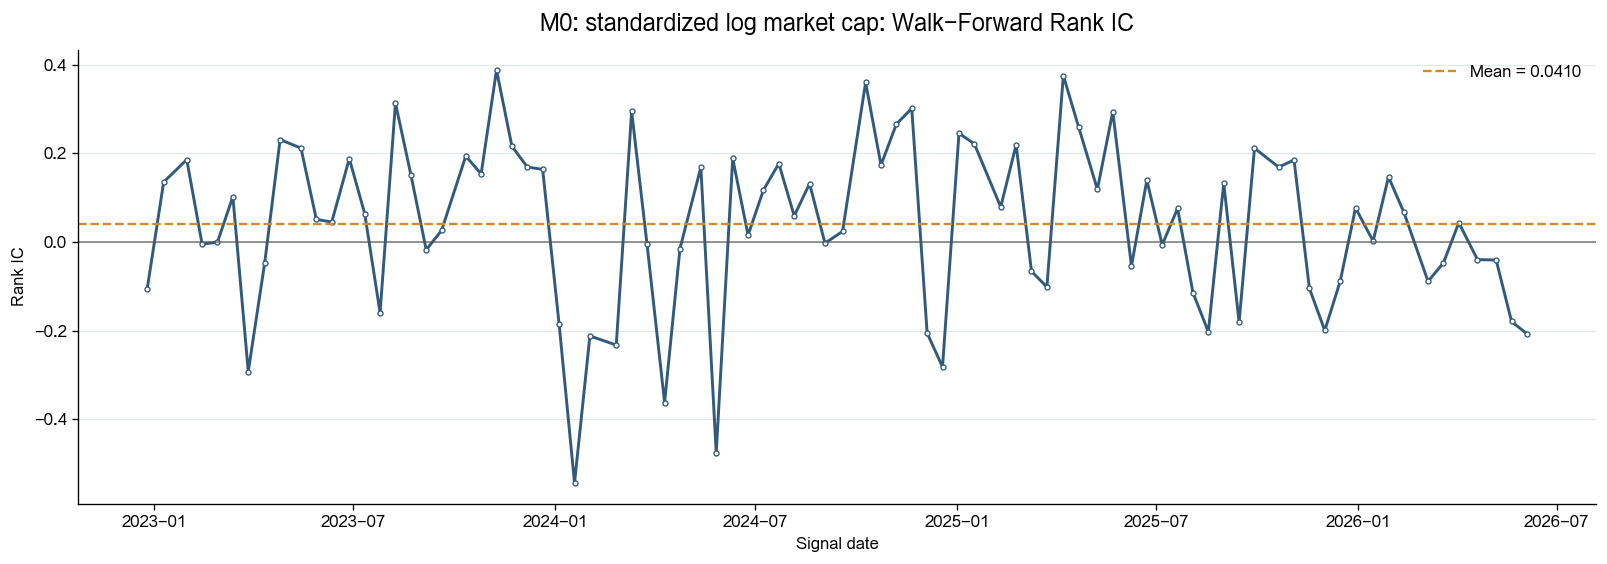

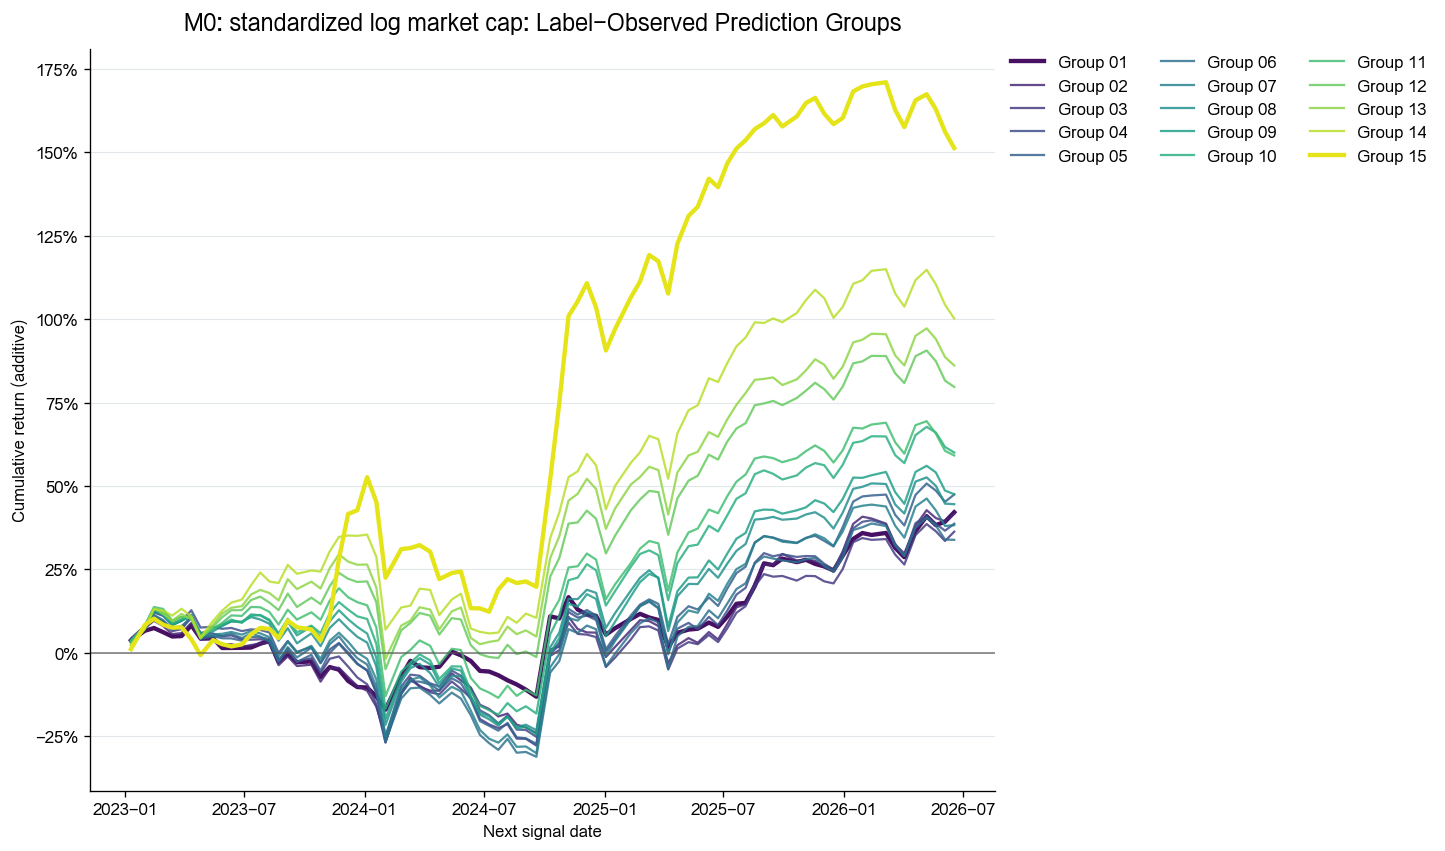

,prediction_group,mean_group_label_coverage,min_group_label_coverage,mean_scored_stocks
0,1,99.9%,99.2%,356.2
1,2,99.9%,99.1%,355.6
2,3,99.9%,99.2%,355.7
3,4,99.9%,99.2%,355.5
4,5,99.9%,99.4%,355.4
5,6,99.9%,99.2%,355.9
6,7,99.9%,99.4%,355.4
7,8,99.9%,99.2%,355.7
8,9,99.9%,99.2%,355.6
9,10,99.9%,99.2%,355.3


M0 已在 84 个信号日完成前向预测；因训练历史或当期特征不足而跳过 48 个信号日。


In [5]:
# Notebook 单元格 3：滚动训练与评价函数。
# 输入的是已处理的特征面板；函数不负责计算、缩尾或标准化任何因子。

from time import perf_counter

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick


def _render_walkforward_progress(
    stage,
    completed=None,
    total=None,
    date=None,
    started_at=None,
):
    """使用固定宽度单行刷新进度，不改变任何计算结果。"""
    detail = ""
    if completed is not None and total:
        detail += f" | {completed}/{total} ({completed / total:.0%})"
    if date is not None:
        detail += f" | {pd.Timestamp(date):%Y-%m-%d}"
    if started_at is not None:
        elapsed = perf_counter() - started_at
        detail += f" | 已用 {elapsed:.0f}s"
        if completed and total and completed < total:
            detail += f" | 预计余 {elapsed / completed * (total - completed):.0f}s"
    line = f"[滚动收益模型] {stage}{detail}"
    print("\r" + line[:120].ljust(120), end="", flush=True)


def _validate_feature_panels(feature_panels):
    """校验并合并 {特征名: date+instrument+特征值} 面板。"""
    if not isinstance(feature_panels, dict) or not feature_panels:
        raise ValueError("feature_panels 必须是非空字典。")

    merged = None
    feature_names = list(feature_panels)
    for feature_name, panel in feature_panels.items():
        if not isinstance(feature_name, str) or not feature_name:
            raise ValueError("feature_panels 的特征名必须是非空字符串。")
        required = {"date", "instrument", feature_name}
        missing = required - set(panel.columns)
        if missing:
            raise ValueError(
                f"特征 {feature_name!r} 缺少字段：{sorted(missing)}"
            )

        current = panel[["date", "instrument", feature_name]].copy()
        current["date"] = pd.to_datetime(current["date"]).dt.normalize()
        current[feature_name] = pd.to_numeric(
            current[feature_name], errors="coerce"
        )
        if current.duplicated(["date", "instrument"]).any():
            raise ValueError(f"特征 {feature_name!r} 存在重复的 date + instrument。")

        merged = (
            current
            if merged is None
            else merged.merge(
                current,
                on=["date", "instrument"],
                how="outer",
                validate="one_to_one",
            )
        )

    return merged, feature_names


def _fit_cross_sectional_coefficients(
    feature_data,
    labels,
    feature_names,
    min_cross_section,
):
    """逐个历史截面拟合 OLS，得到滚动 Fama--MacBeth 所需的系数序列。"""
    train_panel = feature_data.merge(
        labels[
            [
                "date",
                "instrument",
                "return_end_date",
                "forward_return",
                "has_label",
            ]
        ],
        on=["date", "instrument"],
        how="inner",
        validate="one_to_one",
    )
    train_panel = train_panel.loc[
        train_panel["has_label"].eq(True)
    ].replace([np.inf, -np.inf], np.nan).dropna(
        subset=[*feature_names, "forward_return"]
    )

    rows = []
    for date, section in train_panel.groupby("date", sort=True):
        if len(section) < min_cross_section:
            continue

        design = np.column_stack([
            np.ones(len(section)),
            section[feature_names].to_numpy(dtype=float),
        ])
        if np.linalg.matrix_rank(design) != len(feature_names) + 1:
            continue

        coefficients = np.linalg.lstsq(
            design,
            section["forward_return"].to_numpy(dtype=float),
            rcond=None,
        )[0]
        rows.append({
            "date": date,
            "return_end_date": section["return_end_date"].iloc[0],
            "n_train_stocks": len(section),
            "intercept": coefficients[0],
            **dict(zip(feature_names, coefficients[1:])),
        })

    coefficient_history = pd.DataFrame(rows)
    if coefficient_history.empty:
        raise ValueError("没有可用于滚动训练的有效截面回归结果。")
    return coefficient_history.sort_values("date").reset_index(drop=True)


def _assign_prediction_groups(score_panel, group_count, min_cross_section):
    """先在可评分股票上形成组别，再附加标签，避免未来标签影响分组。"""
    grouped_rows = []
    for date, section in score_panel.groupby("date", sort=True):
        if len(section) < max(min_cross_section, group_count):
            continue
        if section["score"].nunique() < 2:
            continue

        current = section.copy()
        current["prediction_group"] = pd.qcut(
            current["score"].rank(method="first"),
            q=group_count,
            labels=range(1, group_count + 1),
        ).astype(int)
        grouped_rows.append(current)

    if not grouped_rows:
        raise ValueError("没有截面能够形成预测分组。")
    return pd.concat(grouped_rows, ignore_index=True)


def _build_walkforward_figures(
    model_name,
    rank_ic_series,
    group_period_returns,
    group_count,
):
    rank_figure, rank_axis = plt.subplots(figsize=(13.5, 4.8), dpi=120)
    valid_rank_ic = rank_ic_series.dropna(subset=["rank_ic"])
    rank_axis.plot(
        valid_rank_ic["date"],
        valid_rank_ic["rank_ic"],
        color="#315A7D",
        linewidth=1.75,
        marker="o",
        markersize=3.0,
        markerfacecolor="white",
        markeredgewidth=0.8,
    )
    rank_axis.axhline(0, color="#555555", linewidth=0.9, alpha=0.8)
    if not valid_rank_ic.empty:
        rank_axis.axhline(
            valid_rank_ic["rank_ic"].mean(),
            color="#D18B2C",
            linewidth=1.4,
            linestyle="--",
            label=f"Mean = {valid_rank_ic['rank_ic'].mean():.4f}",
        )
        rank_axis.legend(frameon=False, loc="best")
    rank_axis.set_title(f"{model_name}: Walk-Forward Rank IC", fontsize=14, pad=12)
    rank_axis.set_xlabel("Signal date")
    rank_axis.set_ylabel("Rank IC")
    rank_axis.grid(axis="y", color="#D8DEE5", linewidth=0.7, alpha=0.7)
    rank_axis.grid(False, axis="x")
    for spine in ("top", "right"):
        rank_axis.spines[spine].set_visible(False)
    rank_figure.tight_layout()
    plt.close(rank_figure)

    group_figure, group_axis = plt.subplots(figsize=(14.5, 7.2), dpi=120)
    colors = plt.get_cmap("viridis")(np.linspace(0.04, 0.96, group_count))
    for group, color in zip(range(1, group_count + 1), colors):
        curve = group_period_returns.loc[
            group_period_returns["prediction_group"].eq(group)
        ]
        if curve.empty:
            continue
        group_axis.plot(
            curve["next_signal_date"],
            curve["cumulative_labeled_return_additive"],
            color=color,
            linewidth=2.6 if group in {1, group_count} else 1.35,
            alpha=1.0 if group in {1, group_count} else 0.84,
            label=f"Group {group:02d}",
        )
    group_axis.axhline(0, color="#555555", linewidth=0.9, alpha=0.8)
    group_axis.set_title(
        f"{model_name}: Label-Observed Prediction Groups",
        fontsize=14,
        pad=12,
    )
    group_axis.set_xlabel("Next signal date")
    group_axis.set_ylabel("Cumulative return (additive)")
    group_axis.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    group_axis.grid(axis="y", color="#D8DEE5", linewidth=0.7, alpha=0.7)
    group_axis.grid(False, axis="x")
    for spine in ("top", "right"):
        group_axis.spines[spine].set_visible(False)
    group_axis.legend(
        ncol=3,
        frameon=False,
        bbox_to_anchor=(1.01, 1),
        loc="upper left",
        borderaxespad=0,
    )
    group_figure.tight_layout(rect=(0, 0, 0.84, 1))
    plt.close(group_figure)

    return rank_figure, group_figure


def run_walkforward_return_model(
    model_name,
    feature_panels,
    labels,
    universe_panel,
    rolling_study,
    show_progress=True,
    progress_every=5,
    progress_label=None,
    finish_progress=True,
    make_figures=True,
):
    """以固定滚动协议训练、预测并评价线性多因子收益模型。

    因子面板必须已完成各自定义的处理与标准化。函数仅负责：
    1. 最近 W 个已完成标签截面的滚动 Fama--MacBeth 估计；
    2. 当前截面的前向预测；
    3. Rank IC、分组标签覆盖率与诊断性分组收益评价。

    labeled_equal_weight_return 不是可交易策略收益：它仅对有完整标签
    的股票计算等权均值，并同时报告覆盖率。真实交易收益需在后续回测层处理。
    """
    if not isinstance(model_name, str) or not model_name.strip():
        raise ValueError("model_name 必须是非空字符串。")
    if not isinstance(show_progress, (bool, np.bool_)):
        raise TypeError("show_progress 必须是 bool。")
    if progress_label is not None and (
        not isinstance(progress_label, str) or not progress_label.strip()
    ):
        raise ValueError("progress_label 必须是 None 或非空字符串。")
    if not isinstance(finish_progress, (bool, np.bool_)):
        raise TypeError("finish_progress 必须是 bool。")
    if not isinstance(make_figures, (bool, np.bool_)):
        raise TypeError("make_figures 必须是 bool。")
    if isinstance(progress_every, (bool, np.bool_)) or not isinstance(
        progress_every, (int, np.integer)
    ) or progress_every <= 0:
        raise ValueError("progress_every 必须是正整数。")

    required_study = {
        "rolling_train_signal_dates",
        "min_cross_section",
        "prediction_group_count",
    }
    missing_study = required_study - set(rolling_study)
    if missing_study:
        raise KeyError(f"rolling_study 缺少字段：{sorted(missing_study)}")

    label_required = {
        "date",
        "instrument",
        "return_end_date",
        "forward_return",
        "next_signal_date",
        "signal_interval_return",
        "has_label",
        "label_missing_reason",
    }
    missing_labels = label_required - set(labels.columns)
    if missing_labels:
        raise ValueError(f"labels 缺少字段：{sorted(missing_labels)}")
    universe_required = {"date", "instrument"}
    missing_universe = universe_required - set(universe_panel.columns)
    if missing_universe:
        raise ValueError(
            f"universe_panel 缺少字段：{sorted(missing_universe)}"
        )

    feature_data, feature_names = _validate_feature_panels(feature_panels)
    labels = labels.copy()
    universe_panel = universe_panel[["date", "instrument"]].copy()
    for panel in (labels, universe_panel):
        panel["date"] = pd.to_datetime(panel["date"]).dt.normalize()

    if labels.duplicated(["date", "instrument"]).any():
        raise ValueError("labels 存在重复的 date + instrument。")
    if universe_panel.duplicated(["date", "instrument"]).any():
        raise ValueError("universe_panel 存在重复的 date + instrument。")

    model_dates = pd.DatetimeIndex(
        labels["date"].unique()
    ).normalize().sort_values()
    universe_panel = universe_panel.loc[
        universe_panel["date"].isin(model_dates)
    ].copy()
    expected_keys = universe_panel[["date", "instrument"]]
    labels = expected_keys.merge(
        labels,
        on=["date", "instrument"],
        how="left",
        validate="one_to_one",
    )
    if labels["has_label"].isna().any():
        raise ValueError("labels 未覆盖部分 universe_panel 股票。")

    # 逐期截面回归序列可预先计算；每个预测日只会读取标签已完成的历史行。
    coefficient_history = _fit_cross_sectional_coefficients(
        feature_data,
        labels,
        feature_names,
        rolling_study["min_cross_section"],
    )

    feature_on_universe = universe_panel.merge(
        feature_data,
        on=["date", "instrument"],
        how="left",
        validate="one_to_one",
    )
    score_rows = []
    parameter_rows = []
    skipped_rows = []
    started_at = perf_counter()
    total_dates = len(model_dates)
    window = rolling_study["rolling_train_signal_dates"]

    for position, signal_date in enumerate(model_dates, start=1):
        if show_progress and (
            position == 1
            or position % progress_every == 0
            or position == total_dates
        ):
            _render_walkforward_progress(
                (
                    "滚动拟合与前向预测"
                    if progress_label is None
                    else f"{progress_label} | 滚动拟合与前向预测"
                ),
                position,
                total_dates,
                signal_date,
                started_at,
            )

        # 在收盘后形成信号；收益终点不晚于当前日的历史截面方可进入训练。
        completed_history = coefficient_history.loc[
            coefficient_history["return_end_date"].le(signal_date),
            ["date", "return_end_date", "intercept", *feature_names],
        ].tail(window)
        if len(completed_history) < window:
            skipped_rows.append({
                "date": signal_date,
                "reason": "insufficient_completed_training_history",
                "available_training_cross_sections": len(completed_history),
            })
            continue

        parameters = completed_history[["intercept", *feature_names]].mean()
        current = feature_on_universe.loc[
            feature_on_universe["date"].eq(signal_date),
            ["date", "instrument", *feature_names],
        ].replace([np.inf, -np.inf], np.nan).dropna(
            subset=feature_names
        ).copy()
        if len(current) < rolling_study["min_cross_section"]:
            skipped_rows.append({
                "date": signal_date,
                "reason": "insufficient_scored_cross_section",
                "available_training_cross_sections": len(completed_history),
            })
            continue

        current["score"] = (
            float(parameters["intercept"])
            + current[feature_names].to_numpy(dtype=float)
            @ parameters[feature_names].to_numpy(dtype=float)
        )
        score_rows.append(current[["date", "instrument", "score"]])
        parameter_rows.append({
            "date": signal_date,
            "training_start_date": completed_history["date"].min(),
            "training_end_date": completed_history["date"].max(),
            "training_cross_sections": len(completed_history),
            **parameters.to_dict(),
        })

    if show_progress and finish_progress:
        print()
    if not score_rows:
        raise ValueError("没有日期具备足够的已完成训练历史和可评分股票。")

    scores = pd.concat(score_rows, ignore_index=True)
    parameter_series = pd.DataFrame(parameter_rows)
    skipped_dates = pd.DataFrame(skipped_rows)

    # 先在所有可评分股票上形成分组，随后才合并标签。
    grouped_scores = _assign_prediction_groups(
        scores,
        rolling_study["prediction_group_count"],
        rolling_study["min_cross_section"],
    )
    prediction_dates = pd.DatetimeIndex(scores["date"].unique())
    scored_panel = universe_panel.merge(
        scores,
        on=["date", "instrument"],
        how="left",
        validate="one_to_one",
    )
    scored_panel = scored_panel.loc[
        scored_panel["date"].isin(prediction_dates)
    ].copy()
    scored_panel["has_score"] = scored_panel["score"].notna()
    evaluation_panel = grouped_scores.merge(
        labels[
            [
                "date",
                "instrument",
                "return_end_date",
                "forward_return",
                "next_signal_date",
                "signal_interval_return",
                "has_label",
                "label_missing_reason",
            ]
        ],
        on=["date", "instrument"],
        how="left",
        validate="one_to_one",
    )

    # Rank IC 仅在有完整标签的股票上计算，但每期均报告评分覆盖率与标签覆盖率。
    rank_rows = []
    for date, score_section in scored_panel.groupby("date", sort=True):
        scored_count = int(score_section["has_score"].sum())
        universe_count = len(score_section)
        evaluation_section = evaluation_panel.loc[
            evaluation_panel["date"].eq(date)
        ]
        complete_label_section = evaluation_section.loc[
            evaluation_section["has_label"].eq(True)
            & evaluation_section["forward_return"].notna()
        ]
        n_rank_ic = len(complete_label_section)
        can_calculate_rank_ic = (
            n_rank_ic >= rolling_study["min_cross_section"]
            and complete_label_section["score"].nunique() >= 2
        )
        rank_rows.append({
            "date": date,
            "return_end_date": (
                evaluation_section["return_end_date"].iloc[0]
                if not evaluation_section.empty else pd.NaT
            ),
            "n_universe": universe_count,
            "n_scored": scored_count,
            "score_coverage": scored_count / universe_count if universe_count else np.nan,
            "n_rank_ic": n_rank_ic,
            "label_coverage_among_scored": (
                n_rank_ic / scored_count if scored_count else np.nan
            ),
            "rank_ic": (
                complete_label_section["score"].corr(
                    complete_label_section["forward_return"],
                    method="spearman",
                )
                if can_calculate_rank_ic else np.nan
            ),
            "rank_ic_available": can_calculate_rank_ic,
        })
    rank_ic_series = pd.DataFrame(rank_rows)

    # 分组在完整的可评分截面上形成；收益仅汇总完整标签，并同步报告组内标签覆盖率。
    group_period_returns = (
        evaluation_panel.groupby(
            ["date", "next_signal_date", "prediction_group"],
            as_index=False,
        )
        .agg(
            n_scored=("instrument", "size"),
            n_complete_labels=("has_label", "sum"),
            labeled_equal_weight_return=(
                "signal_interval_return",
                lambda values: values.dropna().mean() if values.notna().any() else np.nan,
            ),
        )
        .sort_values(["prediction_group", "date"], kind="mergesort")
        .reset_index(drop=True)
    )
    group_period_returns["label_coverage"] = (
        group_period_returns["n_complete_labels"] / group_period_returns["n_scored"]
    )
    group_period_returns["cumulative_labeled_return_additive"] = (
        group_period_returns.groupby("prediction_group")[
            "labeled_equal_weight_return"
        ].cumsum()
    )

    valid_rank_ic = rank_ic_series.loc[
        rank_ic_series["rank_ic_available"]
    ].copy()
    summary = {
        "model": model_name,
        "rank_ic_dates": len(valid_rank_ic),
        "rank_ic_mean": valid_rank_ic["rank_ic"].mean(),
        "rank_ic_std": valid_rank_ic["rank_ic"].std(ddof=1),
        "mean_score_coverage": rank_ic_series["score_coverage"].mean(),
        "mean_label_coverage_among_scored": (
            rank_ic_series["label_coverage_among_scored"].mean()
        ),
    }
    final_group_returns = (
        group_period_returns.groupby("prediction_group", as_index=False)
        .tail(1)
        .set_index("prediction_group")["cumulative_labeled_return_additive"]
    )
    for group in range(1, rolling_study["prediction_group_count"] + 1):
        summary[f"group_{group:02d}_cumulative_labeled_return"] = (
            final_group_returns.get(group, np.nan)
        )
    summary = pd.DataFrame([summary])

    if make_figures:
        rank_figure, group_figure = _build_walkforward_figures(
            model_name,
            rank_ic_series,
            group_period_returns,
            rolling_study["prediction_group_count"],
        )
    else:
        rank_figure, group_figure = None, None
    return {
        "model_name": model_name,
        "feature_names": feature_names,
        "scores": scores,
        "grouped_scores": grouped_scores,
        "evaluation_panel": evaluation_panel,
        "parameter_series": parameter_series,
        "coefficient_history": coefficient_history,
        "skipped_dates": skipped_dates,
        "rank_ic_series": rank_ic_series,
        "group_period_returns": group_period_returns,
        "summary": summary,
        "rank_ic_figure": rank_figure,
        "group_return_figure": group_figure,
    }



### 剩余因子序列计算

In [6]:
# Notebook 单元格 6：预计算并缓存全部候选基础因子的标准化序列。
# 本单元格排除 M0 的 log_market_cap；后续 M1、M2 等筛选直接复用
# candidate_feature_library，不再重复查询原始数据或计算因子。

from collections.abc import Mapping

from factor_lib.factor_hub.discover_factors import discover_factors

try:
    from factor_lib.bigquant_adapters.loader import get_factor_data_requirements
except ModuleNotFoundError:
    from factor_lib.common.data_adapters.bigquant_adapters.loader import (
        get_factor_data_requirements,
    )


CANDIDATE_LIBRARY_CONFIG = {
    # None 表示扫描全部已登记的基础因子；可改为因子名称白名单。
    "candidate_names": None,
    "exclude_factor_names": {"log_market_cap"},
    # 因子库脚本负责因子定义；本单元格统一做外层截面缩尾与 z-score。
    "winsor_lower_quantile": 0.01,
    "winsor_upper_quantile": 0.99,
    # 预热日历按最远回看窗口自动向前延伸，乘数只用于换算交易日与自然日。
    "preheat_calendar_day_multiplier": 3,
    "show_progress": True,
}


def _expand_candidate_instances(factor_name, metadata):
    """将 FACTOR 的 candidate_instances 统一为参数实例列表。"""
    instances = metadata.get("candidate_instances", {"default": {}})
    expanded = []
    if isinstance(instances, Mapping):
        for instance_id, params in instances.items():
            if not isinstance(params, Mapping):
                raise TypeError(
                    f"{factor_name} 的实例 {instance_id!r} 参数必须是字典。"
                )
            expanded.append((str(instance_id), dict(params)))
    elif isinstance(instances, list):
        for item in instances:
            if not isinstance(item, Mapping):
                raise TypeError(f"{factor_name} 的 candidate_instances 项必须是字典。")
            instance_id = item.get("id")
            params = item.get("params", {})
            if not instance_id or not isinstance(params, Mapping):
                raise ValueError(
                    f"{factor_name} 的 candidate_instances 项缺少 id 或 params。"
                )
            expanded.append((str(instance_id), dict(params)))
    else:
        raise TypeError(f"{factor_name} 的 candidate_instances 格式不支持。")
    return expanded or [("default", {})]


def _resolve_factor_output_column(factor_name, metadata, factor_panel):
    """从元数据与实际输出中确定唯一的股票截面因子列。"""
    if factor_name in factor_panel.columns:
        return factor_name

    output_schema = metadata.get("output_schema", {})
    declared = [
        column
        for column in output_schema
        if column not in {"date", "instrument"}
        and column in factor_panel.columns
    ]
    if len(declared) == 1:
        return declared[0]

    available = [
        column
        for column in factor_panel.columns
        if column not in {"date", "instrument"}
    ]
    if len(available) == 1:
        return available[0]
    raise ValueError(
        f"无法确定因子 {factor_name!r} 的输出列；可用列：{available}"
    )


def _raw_dates_for_candidate(target_dates, preheat_calendar, data_window):
    """按因子元数据要求，返回包含预热期的连续交易日历。"""
    lookback = max(
        int(data_window.get("lookback_trading_days", 0)),
        int(data_window.get("minimum_history_observations", 0)),
    )
    target_dates = pd.DatetimeIndex(target_dates).normalize().sort_values()
    positions = {date: position for position, date in enumerate(preheat_calendar)}
    first_position = positions.get(target_dates.min())
    last_position = positions.get(target_dates.max())
    if first_position is None or last_position is None:
        raise ValueError("候选因子目标日期不在预热交易日历中。")
    if first_position < lookback:
        raise ValueError(
            f"预热日历不足：因子需要 {lookback} 个交易日历史数据。"
        )
    return preheat_calendar[first_position - lookback:last_position + 1]


def _standardize_candidate_panel(
    raw_factor_panel,
    source_column,
    candidate_id,
    universe_panel,
    lower_quantile,
    upper_quantile,
    min_cross_section,
):
    """对齐信号日股票池，并按日期缩尾和 z-score，保留全部股票池键。"""
    raw_factor_panel = raw_factor_panel[
        ["date", "instrument", source_column]
    ].copy()
    raw_factor_panel["date"] = pd.to_datetime(
        raw_factor_panel["date"]
    ).dt.normalize()
    raw_factor_panel[source_column] = pd.to_numeric(
        raw_factor_panel[source_column], errors="coerce"
    )
    if raw_factor_panel.duplicated(["date", "instrument"]).any():
        raise ValueError(f"{candidate_id} 的原始因子值存在重复键。")

    aligned = universe_panel.merge(
        raw_factor_panel,
        on=["date", "instrument"],
        how="left",
        validate="one_to_one",
    )
    processed_sections = []
    for _, section in aligned.groupby("date", sort=True):
        current = section.copy()
        valid = current[source_column].dropna()
        if len(valid) < min_cross_section:
            current[candidate_id] = np.nan
            processed_sections.append(current)
            continue

        lower = valid.quantile(lower_quantile)
        upper = valid.quantile(upper_quantile)
        clipped = current[source_column].clip(lower=lower, upper=upper)
        standard_deviation = clipped.std(ddof=0)
        if not np.isfinite(standard_deviation) or standard_deviation <= 0:
            current[candidate_id] = np.nan
        else:
            current[candidate_id] = (
                (clipped - clipped.mean()) / standard_deviation
            )
        processed_sections.append(current)

    return pd.concat(processed_sections, ignore_index=True)[
        ["date", "instrument", candidate_id]
    ]


def prepare_candidate_feature_library(
    labels,
    universe_panel,
    rolling_study,
    config=None,
):
    """计算除已排除因子外的全部基础因子实例，并缓存标准化面板。

    返回：
    - candidate_feature_library：{candidate_id: date+instrument+标准化因子列}
    - candidate_library_audit：每个候选实例的参数、覆盖率和计算状态
    - candidate_library_protocol：本次缓存所依赖的研究协议
    """
    defaults = {
        "candidate_names": None,
        "exclude_factor_names": {"log_market_cap"},
        "winsor_lower_quantile": 0.01,
        "winsor_upper_quantile": 0.99,
        "preheat_calendar_day_multiplier": 3,
        "show_progress": True,
    }
    cfg = dict(defaults)
    if config is not None:
        cfg.update(dict(config))

    lower = cfg["winsor_lower_quantile"]
    upper = cfg["winsor_upper_quantile"]
    if not 0 <= lower < upper <= 1:
        raise ValueError("候选因子缩尾分位数必须满足 0 <= lower < upper <= 1。")
    if (
        isinstance(cfg["preheat_calendar_day_multiplier"], (bool, np.bool_))
        or not isinstance(cfg["preheat_calendar_day_multiplier"], (int, np.integer))
        or cfg["preheat_calendar_day_multiplier"] < 2
    ):
        raise ValueError("preheat_calendar_day_multiplier 必须是不小于 2 的整数。")
    if not isinstance(cfg["show_progress"], (bool, np.bool_)):
        raise TypeError("show_progress 必须是 bool。")

    candidate_whitelist = (
        None
        if cfg["candidate_names"] is None
        else set(cfg["candidate_names"])
    )
    excluded_names = set(cfg["exclude_factor_names"])
    target_dates = pd.DatetimeIndex(labels["date"].unique()).normalize().sort_values()
    universe_panel = universe_panel[["date", "instrument"]].copy()
    universe_panel["date"] = pd.to_datetime(universe_panel["date"]).dt.normalize()
    universe_panel = universe_panel.loc[
        universe_panel["date"].isin(target_dates)
    ].copy()
    if universe_panel.duplicated(["date", "instrument"]).any():
        raise ValueError("universe_panel 存在重复键。")

    metadata_map = discover_factors()
    candidate_specs = []
    for factor_name, metadata in metadata_map.items():
        if metadata.get("factor_type") != "base":
            continue
        if factor_name in excluded_names:
            continue
        if candidate_whitelist is not None and factor_name not in candidate_whitelist:
            continue
        for instance_id, factor_params in _expand_candidate_instances(
            factor_name, metadata
        ):
            candidate_specs.append({
                "candidate_id": f"{factor_name}__{instance_id}",
                "factor_name": factor_name,
                "instance_id": instance_id,
                "factor_params": factor_params,
                "category": metadata.get("category", "unclassified"),
                "metadata": metadata,
            })
    if not candidate_specs:
        raise ValueError("没有发现可预计算的候选基础因子。")

    # 先解析全部候选的最远预热需求，再取得一份足够长的公共交易日历。
    maximum_lookback = 0
    for spec in candidate_specs:
        requirements = get_factor_data_requirements(
            spec["factor_name"],
            spec["factor_params"],
        )
        window = requirements["data_window"]
        maximum_lookback = max(
            maximum_lookback,
            int(window.get("lookback_trading_days", 0)),
            int(window.get("minimum_history_observations", 0)),
        )
    calendar_start = (
        target_dates.min()
        - pd.Timedelta(
            days=max(
                366,
                maximum_lookback * cfg["preheat_calendar_day_multiplier"] + 30,
            )
        )
    )
    preheat_calendar = load_trading_dates(
        calendar_start.strftime("%Y-%m-%d"),
        target_dates.max().strftime("%Y-%m-%d"),
    )
    preheat_calendar = pd.DatetimeIndex(
        preheat_calendar
    ).normalize().sort_values().unique()

    library = {}
    audit_rows = []
    total_candidates = len(candidate_specs)
    for position, spec in enumerate(candidate_specs, start=1):
        candidate_id = spec["candidate_id"]
        if cfg["show_progress"]:
            _render_walkforward_progress(
                f"候选 {position}/{total_candidates} {candidate_id[:28]} | 解析数据窗口",
            )
        try:
            requirements = get_factor_data_requirements(
                spec["factor_name"],
                spec["factor_params"],
            )
            raw_dates = _raw_dates_for_candidate(
                target_dates,
                preheat_calendar,
                requirements["data_window"],
            )

            if cfg["show_progress"]:
                _render_walkforward_progress(
                    f"候选 {position}/{total_candidates} {candidate_id[:28]} | 读取原始数据",
                )
            raw_data = load_factor_raw_data(
                spec["factor_name"],
                dates=raw_dates,
                factor_params=spec["factor_params"],
                instruments=instruments,
                show_progress=False,
            )

            reserved_params = {
                "target_dates",
                "as_of_date",
                "show_progress",
                "progress_every",
            }
            resolved_params = {
                name: value
                for name, value in requirements["resolved_factor_params"].items()
                if name not in reserved_params
            }
            if cfg["show_progress"]:
                _render_walkforward_progress(
                    f"候选 {position}/{total_candidates} {candidate_id[:28]} | 计算因子截面",
                )
            raw_factor_panel = get_factor(
                spec["factor_name"],
                raw_data,
                target_dates=target_dates,
                as_of_date=target_dates.max(),
                show_progress=False,
                **resolved_params,
            )
            source_column = _resolve_factor_output_column(
                spec["factor_name"],
                spec["metadata"],
                raw_factor_panel,
            )

            if cfg["show_progress"]:
                _render_walkforward_progress(
                    f"候选 {position}/{total_candidates} {candidate_id[:28]} | 缩尾与标准化",
                )
            standardized_panel = _standardize_candidate_panel(
                raw_factor_panel=raw_factor_panel,
                source_column=source_column,
                candidate_id=candidate_id,
                universe_panel=universe_panel,
                lower_quantile=lower,
                upper_quantile=upper,
                min_cross_section=rolling_study["min_cross_section"],
            )
            coverage = (
                standardized_panel.groupby("date")[candidate_id]
                .apply(lambda values: values.notna().mean())
            )
            library[candidate_id] = standardized_panel
            audit_rows.append({
                "candidate_id": candidate_id,
                "factor_name": spec["factor_name"],
                "instance_id": spec["instance_id"],
                "category": spec["category"],
                "factor_params": repr(spec["factor_params"]),
                "status": "ok",
                "source_column": source_column,
                "mean_feature_coverage": coverage.mean(),
                "min_feature_coverage": coverage.min(),
                "max_lookback_trading_days": max(
                    int(requirements["data_window"].get("lookback_trading_days", 0)),
                    int(requirements["data_window"].get("minimum_history_observations", 0)),
                ),
            })
        except Exception as exc:
            audit_rows.append({
                "candidate_id": candidate_id,
                "factor_name": spec["factor_name"],
                "instance_id": spec["instance_id"],
                "category": spec["category"],
                "factor_params": repr(spec["factor_params"]),
                "status": "error",
                "error": str(exc)[:500],
            })

    if cfg["show_progress"]:
        print()

    audit = pd.DataFrame(audit_rows)
    protocol = {
        "backtest_start": rolling_study.get("backtest_start"),
        "backtest_end": rolling_study.get("backtest_end"),
        "signal_interval_trading_days": rolling_study.get(
            "signal_interval_trading_days"
        ),
        "prediction_horizon_trading_days": rolling_study.get(
            "prediction_horizon_trading_days"
        ),
        "universe": dict(rolling_study.get("universe", {})),
        "winsor_lower_quantile": lower,
        "winsor_upper_quantile": upper,
        "excluded_factor_names": sorted(excluded_names),
        "candidate_count": total_candidates,
        "success_count": int(audit["status"].eq("ok").sum()),
        "failure_count": int(audit["status"].eq("error").sum()),
    }
    return library, audit, protocol


candidate_feature_library, candidate_library_audit, candidate_library_protocol = (
    prepare_candidate_feature_library(
        labels=labels,
        universe_panel=universe_panel,
        rolling_study=ROLLING_STUDY,
        config=CANDIDATE_LIBRARY_CONFIG,
    )
)

display(
    candidate_library_audit.loc[
        candidate_library_audit["status"].eq("ok")
    ].sort_values(
        ["mean_feature_coverage", "candidate_id"],
        ascending=[False, True],
    ).style.format({
        "mean_feature_coverage": "{:.1%}",
        "min_feature_coverage": "{:.1%}",
    }).set_caption("候选因子库：成功计算的标准化因子实例")
)
if candidate_library_audit["status"].eq("error").any():
    display(
        candidate_library_audit.loc[
            candidate_library_audit["status"].eq("error"),
            ["candidate_id", "factor_name", "factor_params", "error"],
        ].set_caption("候选因子库：计算失败实例")
    )
print("候选因子库协议：", candidate_library_protocol)



[滚动收益模型] 候选 72/72 williams_r_nd__14d | 缩尾与标准化                                                                           


,candidate_id,factor_name,instance_id,category,factor_params,status,source_column,mean_feature_coverage,min_feature_coverage,max_lookback_trading_days
5,dividend_yield__default,dividend_yield,default,valuation,{},ok,dividend_yield,100.0%,100.0%,1
21,intraday_return__default,intraday_return,default,unclassified,{},ok,intraday_return,100.0%,100.0%,0
22,log_price__default,log_price,default,price_level,{},ok,log_price,100.0%,100.0%,1
66,turnover_mean_nm__12m,turnover_mean_nm,12m,liquidity,"{'n_months': 12, 'trading_days_per_month': 21}",ok,turnover_mean_nm,100.0%,100.0%,251
63,turnover_mean_nm__1m,turnover_mean_nm,1m,liquidity,"{'n_months': 1, 'trading_days_per_month': 21}",ok,turnover_mean_nm,100.0%,100.0%,20
64,turnover_mean_nm__3m,turnover_mean_nm,3m,liquidity,"{'n_months': 3, 'trading_days_per_month': 21}",ok,turnover_mean_nm,100.0%,100.0%,62
65,turnover_mean_nm__6m,turnover_mean_nm,6m,liquidity,"{'n_months': 6, 'trading_days_per_month': 21}",ok,turnover_mean_nm,100.0%,100.0%,125
62,turnover_bias_nm__12m,turnover_bias_nm,12m,liquidity,"{'n_months': 12, 'trading_days_per_month': 21}",ok,turnover_bias_nm,100.0%,99.9%,252
61,turnover_bias_nm__6m,turnover_bias_nm,6m,liquidity,"{'n_months': 6, 'trading_days_per_month': 21}",ok,turnover_bias_nm,100.0%,99.9%,126
60,turnover_bias_nm__3m,turnover_bias_nm,3m,liquidity,"{'n_months': 3, 'trading_days_per_month': 21}",ok,turnover_bias_nm,100.0%,99.9%,63


候选因子库协议： {'backtest_start': '2021-01-01', 'backtest_end': '2026-06-30', 'signal_interval_trading_days': 10, 'prediction_horizon_trading_days': 10, 'universe': {'type': 'all_a'}, 'winsor_lower_quantile': 0.01, 'winsor_upper_quantile': 0.99, 'excluded_factor_names': ['log_market_cap'], 'candidate_count': 72, 'success_count': 72, 'failure_count': 0}


### 持久化因子序列

In [8]:
# Notebook 单元格 9：将已计算的候选因子库持久化到 BigQuant DAI 数据表。
# 本单元格应在 candidate_feature_library 成功生成后运行。
# 注意：candidate_id 在每个因子面板内重复，不能作为 BDB 的索引列。

import dai

# 使用新 ID，避免复用此前因错误索引配置而只写入部分数据的缓存表。
CACHE_ID = "leo_factor_cache_2021_2026_k10_v2"
AUDIT_ID = f"{CACHE_ID}_audit"
MANIFEST_ID = f"{CACHE_ID}_manifest"

if dai.DataSource(CACHE_ID).exists():
    raise FileExistsError(
        f"{CACHE_ID} 已存在。请读取既有缓存，或明确设置新的 CACHE_ID；"
        "不要在未知状态下直接向已有表追加数据。"
    )
if dai.DataSource(AUDIT_ID).exists() or dai.DataSource(MANIFEST_ID).exists():
    raise FileExistsError(
        "同名审计表或协议清单已存在；请更换 CACHE_ID。"
    )

cache_data_source = None
candidate_ids = list(candidate_feature_library)
total_candidates = len(candidate_ids)

for position, candidate_id in enumerate(candidate_ids, start=1):
    _render_walkforward_progress(
        f"持久化候选因子 {candidate_id[:28]}",
        position,
        total_candidates,
    )

    payload = candidate_feature_library[candidate_id].rename(
        columns={candidate_id: "factor_value"}
    ).copy()
    payload["candidate_id"] = candidate_id
    payload["date"] = pd.to_datetime(payload["date"]).dt.normalize()
    payload["factor_value"] = pd.to_numeric(
        payload["factor_value"], errors="coerce"
    ).astype("float32")

    # 按年份分区；date 是唯一的 BDB 索引列。
    payload["cache_year"] = payload["date"].dt.year.astype("int16")
    payload = payload[
        ["date", "instrument", "candidate_id", "factor_value", "cache_year"]
    ].sort_values(["date", "instrument"], kind="mergesort")

    if cache_data_source is None:
        cache_data_source = dai.DataSource.write_bdb(
            data=payload,
            id=CACHE_ID,
            partitioning=["cache_year"],
            indexes=["date"],
            unique_together=["date", "instrument", "candidate_id"],
            on_duplicates="last",
            docs={
                "description": (
                    "滚动多因子收益模型研究：已缩尾并标准化的候选因子库。"
                )
            },
        )
    else:
        cache_data_source.insert_bdb(
            payload,
            on_duplicates="last",
        )

print()

# 保存审计表：记录每个因子的参数、覆盖率、预热长度和失败信息。
dai.DataSource.write_bdb(
    data=candidate_library_audit.copy(),
    id=AUDIT_ID,
    unique_together=["candidate_id"],
    on_duplicates="last",
    docs={"description": "候选因子库的计算审计记录。"},
)

# 保存协议清单：读取缓存前必须先核对该协议是否与当前研究一致。
manifest = {
    **candidate_library_protocol,
    "cache_id": CACHE_ID,
    "audit_id": AUDIT_ID,
    "value_column": "factor_value",
    "candidate_ids": sorted(candidate_feature_library),
}
dai.DataSource.write_json(
    manifest,
    id=MANIFEST_ID,
)

print(
    f"候选因子库已持久化：{CACHE_ID}；"
    f"共写入 {len(candidate_ids)} 个候选因子实例。"
)



[滚动收益模型] 持久化候选因子 williams_r_nd__14d | 72/72 (100%)                                                                      


Exception: min/max ('amount_relative_ma_nd__20d', 'williams_r_nd__14d') is not valid, index column candidate_id must be unique

### 增量因子筛选函数

In [ ]:
# Notebook 单元格 7：基于候选因子库的增量因子筛选函数。
# 此函数不重新计算因子；它复用 candidate_feature_library，
# 对每个候选运行“当前模型 + 该候选”的滚动前向评价。

def _candidate_feature_coverage(candidate_panel, candidate_id, universe_panel):
    required = {"date", "instrument", candidate_id}
    missing = required - set(candidate_panel.columns)
    if missing:
        raise ValueError(
            f"候选 {candidate_id!r} 缺少字段：{sorted(missing)}"
        )

    panel = candidate_panel[["date", "instrument", candidate_id]].copy()
    panel["date"] = pd.to_datetime(panel["date"]).dt.normalize()
    panel[candidate_id] = pd.to_numeric(panel[candidate_id], errors="coerce")
    if panel.duplicated(["date", "instrument"]).any():
        raise ValueError(f"候选 {candidate_id!r} 存在重复的 date + instrument。")

    aligned = universe_panel.merge(
        panel,
        on=["date", "instrument"],
        how="left",
        validate="one_to_one",
    )
    coverage = aligned.groupby("date")[candidate_id].apply(
        lambda values: values.notna().mean()
    )
    return coverage


def _operational_rank_ic_comparison(base_result, candidate_result):
    """比较各模型各自可评分样本上的 Rank IC。"""
    base = base_result["rank_ic_series"][
        ["date", "rank_ic", "rank_ic_available"]
    ].rename(columns={
        "rank_ic": "base_rank_ic",
        "rank_ic_available": "base_rank_ic_available",
    })
    candidate = candidate_result["rank_ic_series"][
        ["date", "rank_ic", "rank_ic_available"]
    ].rename(columns={
        "rank_ic": "candidate_rank_ic",
        "rank_ic_available": "candidate_rank_ic_available",
    })
    comparison = base.merge(
        candidate,
        on="date",
        how="inner",
        validate="one_to_one",
    )
    comparison = comparison.loc[
        comparison["base_rank_ic_available"]
        & comparison["candidate_rank_ic_available"]
    ].dropna(subset=["base_rank_ic", "candidate_rank_ic"]).copy()
    comparison["operational_delta_rank_ic"] = (
        comparison["candidate_rank_ic"] - comparison["base_rank_ic"]
    )
    return comparison


def _common_sample_rank_ic_comparison(
    base_result,
    candidate_result,
    labels,
    min_cross_section,
):
    """在两个模型共同评分且拥有完整标签的股票上比较 Rank IC。"""
    base_scores = base_result["scores"].rename(
        columns={"score": "base_score"}
    )
    candidate_scores = candidate_result["scores"].rename(
        columns={"score": "candidate_score"}
    )
    common = base_scores.merge(
        candidate_scores,
        on=["date", "instrument"],
        how="inner",
        validate="one_to_one",
    ).merge(
        labels[
            ["date", "instrument", "forward_return", "has_label"]
        ],
        on=["date", "instrument"],
        how="inner",
        validate="one_to_one",
    )
    common = common.loc[
        common["has_label"].eq(True) & common["forward_return"].notna()
    ].replace([np.inf, -np.inf], np.nan).dropna(
        subset=["base_score", "candidate_score", "forward_return"]
    )

    rows = []
    for date, section in common.groupby("date", sort=True):
        if (
            len(section) < min_cross_section
            or section["base_score"].nunique() < 2
            or section["candidate_score"].nunique() < 2
        ):
            continue
        base_rank_ic = section["base_score"].corr(
            section["forward_return"],
            method="spearman",
        )
        candidate_rank_ic = section["candidate_score"].corr(
            section["forward_return"],
            method="spearman",
        )
        rows.append({
            "date": date,
            "n_common_stocks": len(section),
            "base_common_rank_ic": base_rank_ic,
            "candidate_common_rank_ic": candidate_rank_ic,
            "common_delta_rank_ic": candidate_rank_ic - base_rank_ic,
        })
    return pd.DataFrame(rows).dropna(
        subset=[
            "base_common_rank_ic",
            "candidate_common_rank_ic",
            "common_delta_rank_ic",
        ]
    )


def screen_next_factor(
    base_model_result,
    selected_feature_panels,
    candidate_feature_library,
    labels,
    universe_panel,
    rolling_study,
    min_feature_coverage=0.80,
    min_comparable_dates=24,
    candidate_names=None,
    show_progress=True,
    model_progress_every=5,
):
    """筛选在当前模型基础上最能提升滚动 Rank IC 的一个候选因子。

    筛选主指标为共同可评分股票上的平均 Rank IC 增量，避免候选因子
    因缺失值改变评分样本后，造成看似提升的假象。实际样本上的增量、
    覆盖率及早晚阶段稳定性同时返回，供研究判断。

    只保留排名第一候选的完整模型结果；其余候选仅保留审计摘要，
    避免在内存中持有大量重复的分数、参数和图表。
    """
    if not isinstance(selected_feature_panels, dict) or not selected_feature_panels:
        raise ValueError("selected_feature_panels 必须是非空字典。")
    if not isinstance(candidate_feature_library, dict) or not candidate_feature_library:
        raise ValueError("candidate_feature_library 必须是非空字典。")
    if not 0 < min_feature_coverage <= 1:
        raise ValueError("min_feature_coverage 必须在 (0, 1] 内。")
    if (
        isinstance(min_comparable_dates, (bool, np.bool_))
        or not isinstance(min_comparable_dates, (int, np.integer))
        or min_comparable_dates <= 0
    ):
        raise ValueError("min_comparable_dates 必须是正整数。")
    if not isinstance(show_progress, (bool, np.bool_)):
        raise TypeError("show_progress 必须是 bool。")

    required_result = {"scores", "rank_ic_series"}
    missing_base = required_result - set(base_model_result)
    if missing_base:
        raise ValueError(f"base_model_result 缺少字段：{sorted(missing_base)}")

    selected_names = set(selected_feature_panels)
    candidate_name_filter = (
        None if candidate_names is None else set(candidate_names)
    )
    candidate_ids = [
        candidate_id
        for candidate_id in candidate_feature_library
        if candidate_id not in selected_names
        and (
            candidate_name_filter is None
            or candidate_id in candidate_name_filter
        )
    ]
    if not candidate_ids:
        raise ValueError("没有可供筛选的候选因子。")

    universe_panel = universe_panel[["date", "instrument"]].copy()
    universe_panel["date"] = pd.to_datetime(universe_panel["date"]).dt.normalize()
    labels = labels.copy()
    labels["date"] = pd.to_datetime(labels["date"]).dt.normalize()

    audit_rows = []
    best_rank_key = None
    best_candidate = None
    best_result = None
    best_common_series = None
    total_candidates = len(candidate_ids)

    for position, candidate_id in enumerate(candidate_ids, start=1):
        candidate_panel = candidate_feature_library[candidate_id]
        prefix = f"候选 {position}/{total_candidates} {candidate_id[:24]}"

        try:
            if show_progress:
                _render_walkforward_progress(f"{prefix} | 检查因子覆盖率")
            coverage_series = _candidate_feature_coverage(
                candidate_panel,
                candidate_id,
                universe_panel,
            )
            mean_coverage = coverage_series.mean()
            min_coverage = coverage_series.min()
            if (
                not np.isfinite(mean_coverage)
                or mean_coverage < min_feature_coverage
            ):
                audit_rows.append({
                    "candidate_id": candidate_id,
                    "status": "low_feature_coverage",
                    "mean_feature_coverage": mean_coverage,
                    "min_feature_coverage": min_coverage,
                })
                continue

            candidate_feature_panels = {
                **selected_feature_panels,
                candidate_id: candidate_panel,
            }
            candidate_result = run_walkforward_return_model(
                model_name=f"{base_model_result.get('model_name', 'base')} + {candidate_id}",
                feature_panels=candidate_feature_panels,
                labels=labels,
                universe_panel=universe_panel,
                rolling_study=rolling_study,
                show_progress=show_progress,
                progress_every=model_progress_every,
                progress_label=prefix,
                finish_progress=False,
                make_figures=False,
            )

            operational = _operational_rank_ic_comparison(
                base_model_result,
                candidate_result,
            )
            common = _common_sample_rank_ic_comparison(
                base_model_result,
                candidate_result,
                labels,
                rolling_study["min_cross_section"],
            )
            if len(common) < min_comparable_dates:
                audit_rows.append({
                    "candidate_id": candidate_id,
                    "status": "too_few_common_dates",
                    "mean_feature_coverage": mean_coverage,
                    "min_feature_coverage": min_coverage,
                    "operational_dates": len(operational),
                    "common_dates": len(common),
                })
                continue

            midpoint = len(common) // 2
            candidate_summary = candidate_result["summary"].iloc[0]
            audit_row = {
                "candidate_id": candidate_id,
                "status": "ok",
                "mean_feature_coverage": mean_coverage,
                "min_feature_coverage": min_coverage,
                "mean_candidate_score_coverage": candidate_summary[
                    "mean_score_coverage"
                ],
                "operational_dates": len(operational),
                "base_rank_ic_mean": operational["base_rank_ic"].mean(),
                "candidate_rank_ic_mean": operational[
                    "candidate_rank_ic"
                ].mean(),
                "operational_delta_rank_ic_mean": operational[
                    "operational_delta_rank_ic"
                ].mean(),
                "common_dates": len(common),
                "mean_common_stocks": common["n_common_stocks"].mean(),
                "base_common_rank_ic_mean": common[
                    "base_common_rank_ic"
                ].mean(),
                "candidate_common_rank_ic_mean": common[
                    "candidate_common_rank_ic"
                ].mean(),
                "common_delta_rank_ic_mean": common[
                    "common_delta_rank_ic"
                ].mean(),
                "common_delta_rank_ic_positive_fraction": common[
                    "common_delta_rank_ic"
                ].gt(0).mean(),
                "early_half_common_delta_rank_ic": common.iloc[:midpoint][
                    "common_delta_rank_ic"
                ].mean(),
                "late_half_common_delta_rank_ic": common.iloc[midpoint:][
                    "common_delta_rank_ic"
                ].mean(),
                "skipped_prediction_dates": len(candidate_result["skipped_dates"]),
            }
            audit_rows.append(audit_row)

            rank_key = (
                audit_row["common_delta_rank_ic_mean"],
                audit_row["operational_delta_rank_ic_mean"],
                audit_row["mean_feature_coverage"],
            )
            if best_rank_key is None or rank_key > best_rank_key:
                best_rank_key = rank_key
                best_candidate = candidate_id
                best_result = candidate_result
                best_common_series = common

        except Exception as exc:
            audit_rows.append({
                "candidate_id": candidate_id,
                "status": "error",
                "error": str(exc)[:500],
            })

    if show_progress:
        print()

    audit = pd.DataFrame(audit_rows)
    ranking = audit.loc[audit["status"].eq("ok")].copy()
    if ranking.empty:
        raise RuntimeError("没有候选因子通过覆盖率和共同日期要求。")
    ranking = ranking.sort_values(
        [
            "common_delta_rank_ic_mean",
            "operational_delta_rank_ic_mean",
            "mean_feature_coverage",
        ],
        ascending=False,
        kind="mergesort",
    ).reset_index(drop=True)

    # 按最终排名校正最佳结果，保证返回对象与 ranking 第一行严格一致。
    ranked_best_id = ranking.loc[0, "candidate_id"]
    if ranked_best_id != best_candidate:
        raise RuntimeError("候选排序与保留的最佳模型结果不一致。")

    # 候选循环中不绘图以节省资源；仅为最终第一名补建两张评价图。
    rank_figure, group_figure = _build_walkforward_figures(
        best_result["model_name"],
        best_result["rank_ic_series"],
        best_result["group_period_returns"],
        rolling_study["prediction_group_count"],
    )
    best_result["rank_ic_figure"] = rank_figure
    best_result["group_return_figure"] = group_figure

    return {
        "ranking": ranking,
        "audit": audit,
        "best_candidate_id": best_candidate,
        "best_candidate_panel": candidate_feature_library[best_candidate],
        "best_model_result": best_result,
        "best_common_rank_ic_series": best_common_series,
        "selected_feature_names": list(selected_feature_panels),
        "config": {
            "min_feature_coverage": min_feature_coverage,
            "min_comparable_dates": min_comparable_dates,
            "model_progress_every": model_progress_every,
        },
    }



### 筛选M1增量因子